In [4]:
import os
import glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, Input, mixed_precision
from sklearn.model_selection import train_test_split
import cv2
import keras
print("library loaded successfully")
print("*"*100)


library loaded successfully
****************************************************************************************************


In [5]:
import tensorflow as tf

print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print(f"GPU Detected: {len(gpus)}")
    for gpu in gpus:
        print(f" - {gpu.name}")
else:
    print("No GPU detected. Running on CPU.")

TensorFlow Version: 2.21.0
GPU Detected: 1
 - /physical_device:GPU:0


In [53]:
%matplotlib inline

import os
import cv2
import gc
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
@tf.keras.utils.register_keras_serializable()
class KerasPCCLayer(layers.Layer):
    """Natively computes spatial Pearson Correlation Coefficients within the network graph."""
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        # We used epsilon sothat standard deviation value cannot be zero, otherwise code will crash
        epsilon = 1e-8
        # finds the average standard deviaiton
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        # data normalization or (Z-Score)
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return layers.Flatten()(pcc_matrix)
@keras.saving.register_keras_serializable()
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)
def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)
def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + dice_loss(y_true, y_pred)
def focal_tversky_loss(y_true, y_pred, alpha=0.7, beta=0.3, gamma=0.75):
    """
    Focal Tversky Loss for imbalanced medical image segmentation.
    alpha: controls penalty for False Negatives (FN) -> keeping it higher (0.7) focuses on small polyps.
    beta: controls penalty for False Positives (FP).
    """
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Calculate True Positives, False Negatives, and False Positives
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    
    # Tversky Index
    smooth = 1e-6
    tversky_index = (tp + smooth) / (tp + alpha * fn + beta * fp + smooth)
    
    # Focal Tversky Loss
    return tf.math.pow((1.0 - tversky_index), gamma)
@keras.saving.register_keras_serializable()
def iou_metric(y_true, y_pred):
    y_true_f = tf.cast(y_true, tf.float32)
    y_pred_f = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + 1.0) / (union + 1.0)
@keras.saving.register_keras_serializable()
def tnr_metric(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)

    true_negatives = tf.reduce_sum(tf.cast((1.0 - y_true_f) * (1.0 - y_pred_f), tf.float32))
    false_positives = tf.reduce_sum(tf.cast((1.0 - y_true_f) * y_pred_f, tf.float32))
    
    # TNR = TN / (TN + FP)
    return (true_negatives + 1e-7) / (true_negatives + false_positives + 1e-7)
@keras.saving.register_keras_serializable()
def mean_iou_metric(y_true, y_pred):
    # Flatten the matrices to 1D tensors to calculate pixel-level metrics
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Apply hard thresholding (Same as your F2 and Dice implementation)
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    # Calculate basic confusion matrix components for the positive class (Polyp)
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))
    
    # Calculate True Negatives (TN) which represents correctly classified background pixels
    tn = tf.reduce_sum((1.0 - y_true_f) * (1.0 - y_pred_f))

    # ─── 🎯 STEP 1: CALCULATE IoU FOR POLYP CLASS (Positive Class) ───
    polyp_iou = (tp + 1e-7) / (tp + fp + fn + 1e-7)
    
    # ─── 🌍 STEP 2: CALCULATE IoU FOR BACKGROUND CLASS (Negative Class) ───
    # For background: TN is True Positive, FN becomes False Positive, and FP becomes False Negative
    bg_iou = (tn + 1e-7) / (tn + fn + fp + 1e-7)
    
    # ─── 📊 STEP 3: COMPUTE THE MEAN (AVERAGE) IoU OF BOTH CLASSES ───
    mIoU = (polyp_iou + bg_iou) / 2.0
    
    return mIoU
@keras.saving.register_keras_serializable()
def f2_segmentation(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))

    numerator = 5.0 * tp + 1e-7
    denominator = 5.0 * tp + 4.0 * fn + fp + 1e-7
    
    return numerator / denominator
@keras.saving.register_keras_serializable()
def precision_segmentation(y_true, y_pred):
    # Flatten the matrices to 1D tensors to calculate pixel-level metrics
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Apply hard thresholding (Same as your F2 and mIoU implementation)
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    # Calculate True Positives (TP) and False Positives (FP)
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    
    # Precision Formula: TP / (TP + FP)
    # Adding a tiny epsilon (1e-7) to completely avoid zero division errors
    numerator = tp + 1e-7
    denominator = tp + fp + 1e-7
    
    return numerator / denominator
# ─────────────────────────────────────────────────────────────────────────────
# ⚙️ GLOBAL INFERENCE CONFIGURATIONS & ELM ARTIFACTS LINKING
# ─────────────────────────────────────────────────────────────────────────────
IMG_SIZE = 256

class NumpyFeatureSelector:
    """Stand-in for sklearn's SelectKBest at inference time — all we need is
    the column indices it kept, not the fitted statistics."""
    def __init__(self, indices):
        self.indices = np.asarray(indices, dtype=np.int32)

    def transform(self, X):
        return X[:, self.indices]


def load_elm_artifacts(path):
    data = np.load(path)
    ensemble_weights = [data['ensemble_weights'][i] for i in range(data['ensemble_weights'].shape[0])]

    scaler = RobustScaler()
    scaler.center_ = data['scaler_center_']
    scaler.scale_ = data['scaler_scale_']
    scaler.n_features_in_ = scaler.center_.shape[0]

    selector = NumpyFeatureSelector(data['selector_support'])

    return data['W_input'], data['b_input'], ensemble_weights, scaler, selector

# Prefer whatever is already in this notebook's memory (e.g. you just ran the
# training script in this same session). Otherwise fall back to the saved
# .npz file on disk, so you never have to re-run training just to test.
try:
    GLOBAL_W_input = W_input
    GLOBAL_b_input = b_input
    GLOBAL_ensemble_weights = ensemble_weights
    GLOBAL_scaler = scaler
    GLOBAL_selector = selector
    print("✅ [ELM LINK LOCKED] Using ELM engine already in memory (this session's training run).")
except NameError:
    if os.path.exists(ELM_ARTIFACT_PATH):
        print(f"⏳ ELM engine not found in memory — loading saved artifacts from: {ELM_ARTIFACT_PATH}")
        GLOBAL_W_input, GLOBAL_b_input, GLOBAL_ensemble_weights, GLOBAL_scaler, GLOBAL_selector = load_elm_artifacts(ELM_ARTIFACT_PATH)
        print("✅ [ELM LINK LOCKED] Successfully loaded the saved Ensemble ELM Engine & Selector from disk!")
    else:
        raise RuntimeError(
            f"❌ [CRITICAL] No ELM weights in memory and no saved artifacts found at:\n"
            f"    {ELM_ARTIFACT_PATH}\n"
            f"Run the ELM training script once (it now saves this file automatically) — after that "
            f"you only need this inference script."
        )
# ─────────────────────────────────────────────────────────────────────────────
# 🎨 REFINED IMAGE LABELED LOCALIZATION ENGINE
# ─────────────────────────────────────────────────────────────────────────────
def draw_bounding_box(image, mask):
    res_img = image.copy()
    mask_uint8 = (mask > 0.5).astype(np.uint8) * 255
    contours, _ = cv2.findContours(mask_uint8, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    pixel_to_cm_ratio = 50

    for cnt in contours:
        if cv2.contourArea(cnt) < 10:
            continue

        x, y, w, h = cv2.boundingRect(cnt)
        width_cm = w / pixel_to_cm_ratio
        height_cm = h / pixel_to_cm_ratio
        size_text = f"Polyp: {width_cm:.1f}cm x {height_cm:.1f}cm"
        cv2.rectangle(res_img, (x, y), (x + w, y + h), (0, 255, 0), 2)
        text_y = y - 10 if y - 10 > 20 else y + h + 20
        cv2.putText(res_img, size_text, (x + 1, text_y + 1),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 2, cv2.LINE_AA)
        cv2.putText(res_img, size_text, (x, text_y),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 255, 0), 1, cv2.LINE_AA)
    return res_img

# ─────────────────────────────────────────────────────────────────────────────
# 🔮 MULTI-TASK INFERENCE CORE PIPELINE (FIXED FOR SELECTION & SCALING)
# ─────────────────────────────────────────────────────────────────────────────
def test_and_display(model, feature_extractor, image_path, optimal_threshold=0.47, output_filename='result.png'):
    img = cv2.imread(image_path)
    if img is None:
        raise FileNotFoundError(f"❌ Target frame could not be loaded at: {image_path}")
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (IMG_SIZE, IMG_SIZE))
    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    limg = cv2.merge((cl, a_channel, b_channel))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    median_blur = cv2.medianBlur(enhanced_img, 3)
    sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)

    inp = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)


    pred_outputs = model.predict(inp, verbose=0)
    pred_mask_spatial = pred_outputs[0][0]

    feats = feature_extractor(inp, training=False)
    feats_flat = tf.reshape(feats, [tf.shape(feats)[0], -1]).numpy().flatten().reshape(1, -1).astype(np.float32)

    feats_selected = GLOBAL_selector.transform(feats_flat).astype(np.float32)


    feats_scaled = GLOBAL_scaler.transform(feats_selected).astype(np.float32)

    H_inst = np.tanh(np.dot(feats_scaled, GLOBAL_W_input) + GLOBAL_b_input)


    all_raw = []
    for W_out in GLOBAL_ensemble_weights:
        raw = np.dot(H_inst, W_out)
        all_raw.append(raw)

    final_score = np.mean(all_raw)

    clf_probability = 1 / (1 + np.exp(-final_score))


    mask_bin = (pred_mask_spatial > 0.5).astype(np.uint8)
    mask_3d = np.concatenate([mask_bin] * 3, axis=-1)
    extracted = (img_res * mask_3d).astype(np.uint8)
    detected_img = draw_bounding_box(img_res, pred_mask_spatial)


    if clf_probability >= optimal_threshold:
        diagnostic_text = f"DIAGNOSIS: POLYP DETECTED ({clf_probability * 100:.2f}% Match Score)"
        title_color = '#dd0000' # Vibrant Green
    else:
        diagnostic_text = f"DIAGNOSIS: NON-POLYP ({(1.0 - clf_probability) * 100:.2f}% Clean Score)"
        title_color = '#1faa00' # Deep Red #


    titles = ['(a) Original Frame', '(b) Predicted Mask', '(c) Extracted Region', '(d) Localization View']
    display_images = [img_res, pred_mask_spatial.squeeze(), extracted, detected_img]

    fig, axes = plt.subplots(1, 4, figsize=(20, 5))
    for i in range(4):
        axes[i].imshow(display_images[i], cmap='gray' if i == 1 else None)
        axes[i].set_title(titles[i], fontsize=13, fontweight='bold', pad=12)
        axes[i].axis('off')
    axes[0].text(0.5, -0.05, '(a)', fontsize=14, fontweight='bold', ha='center', va='center', transform=axes[0].transAxes)
    axes[1].text(0.5, -0.05, '(b)', fontsize=14, fontweight='bold', ha='center', va='center', transform=axes[1].transAxes)
    axes[2].text(0.5, -0.05, '(c)', fontsize=14, fontweight='bold', ha='center', va='center', transform=axes[2].transAxes)
    axes[3].text(0.5, -0.05, '(d)', fontsize=14, fontweight='bold', ha='center', va='center', transform=axes[3].transAxes)
    plt.suptitle(diagnostic_text, fontsize=16, fontweight='bold', color=title_color, y=1.04)
    plt.tight_layout()

    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    print(f"🏆 [ELM SUCCESS] Qualitative evaluation plot saved to: {output_filename}")
    plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# 🏃‍♂️ EXECUTION PIPELINE LOOP
# ─────────────────────────────────────────────────────────────────────────────

⏳ ELM engine not found in memory — loading saved artifacts from: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/elm_artifacts.npz
✅ [ELM LINK LOCKED] Successfully loaded the saved Ensemble ELM Engine & Selector from disk!


⏳ Loading Keras Architecture Graph & Setting Cut-off point...
✅ Multi-Task Graph integrated with ELM Input Pipeline at layer 'clf_pcc_layer'.

🎬 Processing Positive Dataset Specimen 1...
🏆 [ELM SUCCESS] Qualitative evaluation plot saved to: thesis_positive_result.png


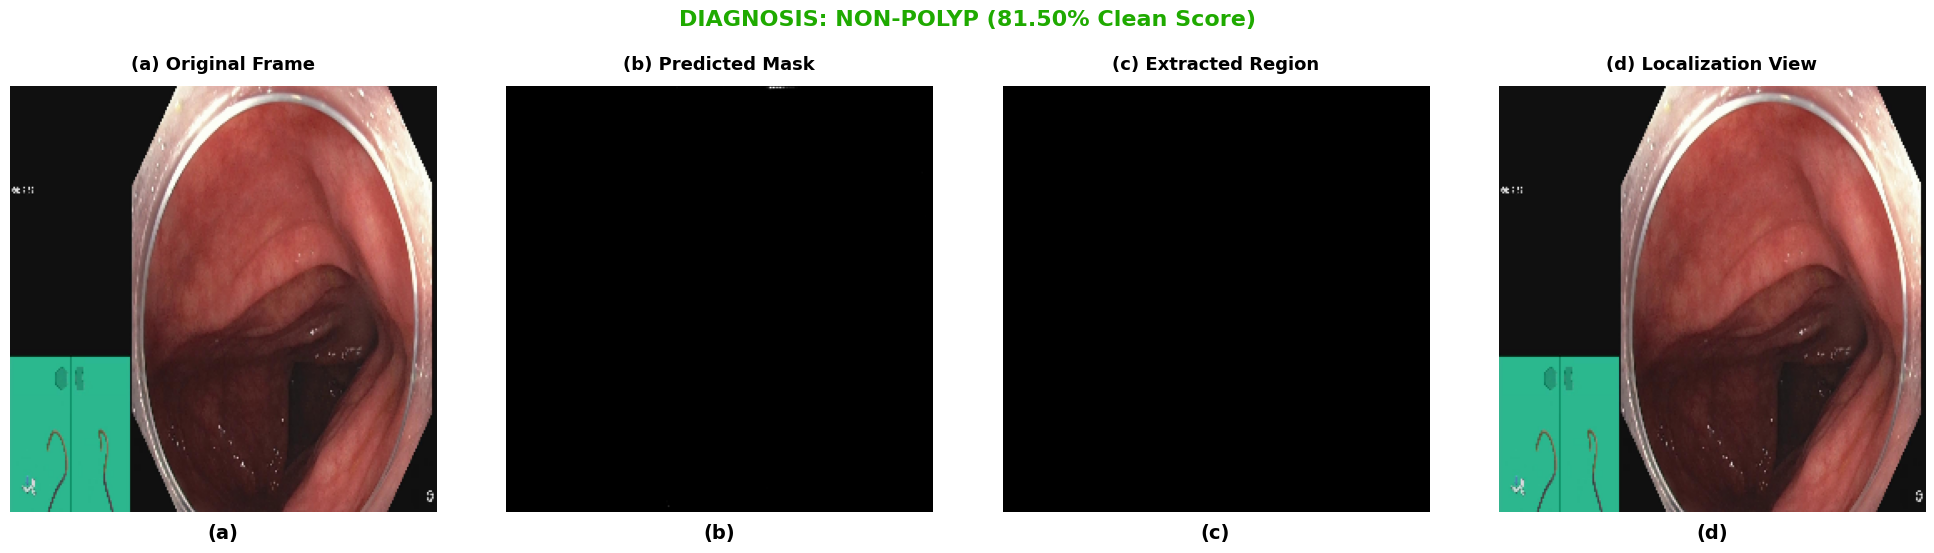

In [55]:
def detect_polyp_function(ELM_ARTIFACT_PATH, MODEL_PATH, TEST_POSITIVE_IMAGE_PATH):
    print("⏳ Loading Keras Architecture Graph & Setting Cut-off point...")
    shared_model = tf.keras.models.load_model(MODEL_PATH, compile=False)
    try:
        target_layer = 'clf_pcc_layer'
        _ = shared_model.get_layer(target_layer)
    except Exception:
        target_layer = 'clf_gap'
    inference_extractor = tf.keras.Model(inputs=shared_model.input, outputs=shared_model.get_layer(target_layer).output)
    print(f"✅ Multi-Task Graph integrated with ELM Input Pipeline at layer '{target_layer}'.\n")
    VAL_BEST_THRESH = 0.60
    print("🎬 Processing Positive Dataset Specimen 1...")
    test_and_display(shared_model, inference_extractor, TEST_POSITIVE_IMAGE_PATH, VAL_BEST_THRESH, 'thesis_positive_result.png')
ELM_ARTIFACT_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/elm_artifacts.npz"
MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
TEST_POSITIVE_IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/sequenceData/negativeOnly/seq8_neg/EndoCV2021_seq8_neg_45_endocv2021_negative_1495.jpg"
detect_polyp_function(ELM_ARTIFACT_PATH, MODEL_PATH, TEST_POSITIVE_IMAGE_PATH)

# Occulation Sencitivity

In [42]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)
        
    def call(self, inputs):
        batch_size = tf.shape(inputs)[0]
        return tf.zeros((batch_size, 1024), dtype=inputs.dtype)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], 1024)

    def get_config(self):
        return super(KerasPCCLayer, self).get_config()

def analyze_occlusion_sensitivity(image_path, model_path, output_dir="./occlusion_output", img_size=256, patch_size=32, stride=16):
    """
    Loads a model and an image, computes the occlusion sensitivity map, 
    displays the result, and saves it to the output directory.
    """
    
    # 1. Setup output directory
    os.makedirs(output_dir, exist_ok=True)
    
    # 2. Load the model
    print("⏳ Loading trained model safely...")
    try:
        model = tf.keras.models.load_model(
            model_path, 
            custom_objects={'KerasPCCLayer': KerasPCCLayer}, 
            compile=False
        )
    except Exception as e:
        print(f"⚠️ Error loading model: {e}")
        return
        
    # 3. Read and preprocess image
    if not os.path.exists(image_path):
        print(f"⚠️ Error: Image file missing at: {image_path}")
        return
        
    raw_bgr = cv2.imread(image_path)
    if raw_bgr is None:
        print(f"⚠️ Error: OpenCV could not read the image at: {image_path}")
        return
        
    orig_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    resized_rgb = cv2.resize(orig_rgb, (img_size, img_size))
    normalized_tensor = np.expand_dims(resized_rgb / 255.0, axis=0)
    
    # 4. Compute Occlusion Sensitivity
    print("🧠 Computing Occlusion Sensitivity Map (this may take a moment)...")
    raw_img = normalized_tensor[0]
    h, w, _ = raw_img.shape
    
    base_preds = model(normalized_tensor, training=False)
    base_mask = base_preds[0][0].numpy() if isinstance(base_preds, (list, tuple)) else base_preds[0].numpy()
    base_score = np.mean(base_mask)
    
    sensitivity_map = np.zeros((h, w), dtype=np.float32)
    heatmap_overlap_counts = np.zeros((h, w), dtype=np.float32)

    for y in range(0, h - patch_size + 1, stride):
        for x in range(0, w - patch_size + 1, stride):
            masked_img = np.copy(raw_img)
            masked_img[y:y+patch_size, x:x+patch_size, :] = 0.5
            masked_tensor = np.expand_dims(masked_img, axis=0)
            
            occluded_preds = model(masked_tensor, training=False)
            occluded_mask = occluded_preds[0][0].numpy() if isinstance(occluded_preds, (list, tuple)) else occluded_preds[0].numpy()
            occluded_score = np.mean(occluded_mask)
            
            score_drop = max(0, base_score - occluded_score)
            sensitivity_map[y:y+patch_size, x:x+patch_size] += score_drop
            heatmap_overlap_counts[y:y+patch_size, x:x+patch_size] += 1.0

    # Normalize Map
    heatmap_overlap_counts[heatmap_overlap_counts == 0] = 1.0
    sensitivity_map /= heatmap_overlap_counts
    
    map_min, map_max = sensitivity_map.min(), sensitivity_map.max()
    if map_max - map_min > 1e-5:
        sensitivity_map = (sensitivity_map - map_min) / (map_max - map_min)
        
    # 5. Visualization & Saving
    heatmap = cv2.applyColorMap(np.uint8(255 * sensitivity_map), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay_img = cv2.addWeighted(resized_rgb, 0.6, heatmap_rgb, 0.4, 0)
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    axes[0].imshow(resized_rgb)
    axes[0].set_title("Original Image", fontsize=12)
    axes[0].axis("off")
    
    axes[1].imshow(sensitivity_map, cmap="jet")
    axes[1].set_title("Occlusion Heatmap", fontsize=12)
    axes[1].axis("off")
    
    axes[2].imshow(overlay_img)
    axes[2].set_title("Explanatory Occlusion Overlay", fontsize=12)
    axes[2].axis("off")
    axes[0].text(0.5, -0.05, '(a)', fontsize=14, fontweight='bold', ha='center', va='center', transform=axes[0].transAxes)
    axes[1].text(0.5, -0.05, '(b)', fontsize=14, fontweight='bold', ha='center', va='center', transform=axes[1].transAxes)
    axes[2].text(0.5, -0.05, '(c)', fontsize=14, fontweight='bold', ha='center', va='center', transform=axes[2].transAxes)
    plt.tight_layout()
    
    # Save target visualizations directly to local directory
    filename = os.path.basename(image_path).split('.')[0] + "_occlusion.png"
    output_path = os.path.join(output_dir, filename)
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()
    
    print(f"🏆 Visualization compiled and saved cleanly at: {output_path}")
    return output_path

In [9]:
import os
import cv2
import numpy as np
import tensorflow as tf
import shap
import matplotlib.pyplot as plt

# ==============================================================================
# ১. কাস্টম লেয়ার (গ্লোবালি রাখা হলো যাতে Keras মডেল লোড করার সময় এটি সহজেই পায়)
# ==============================================================================
@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)
        
    def call(self, inputs):
        epsilon = 1e-8
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return tf.keras.layers.Flatten()(pcc_matrix)
        
    def get_config(self):
        return super().get_config()


# ==============================================================================
# ২. মূল SHAP ফাংশন
# ==============================================================================
def generate_shap_explanation(
    image_path, 
    model_path, 
    elm_artifact_path, 
    output_png="shap_image_explanation.png", 
    img_size=(256, 256), 
    max_evals=300, 
    batch_size=32
):
    """
    Keras + ELM Ensemble মডেল দিয়ে কোনো ইমেজের SHAP explanation জেনারেট করার ফাংশন।
    
    রিটার্ন করবে: (prediction_probability, shap_values)
    """
    
    # ইনপুট ফাইলগুলো আছে কিনা চেক করা
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"মডেল ফাইল পাওয়া যায়নি: {model_path}")
    if not os.path.exists(elm_artifact_path):
        raise FileNotFoundError(f"ELM artifact ফাইল পাওয়া যায়নি: {elm_artifact_path}")
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"ইমেজ ফাইল পাওয়া যায়নি: {image_path}")

    print("⏳ Loading model and ELM artifacts...")
    
    # 2.1 মডেল এবং ফিচার এক্সট্রাক্টর লোড করা
    model = tf.keras.models.load_model(model_path, custom_objects={'KerasPCCLayer': KerasPCCLayer}, compile=False)
    feature_extractor = tf.keras.Model(inputs=model.input, outputs=model.get_layer('clf_pcc_layer').output)

    # 2.2 ELM artifacts লোড করা
    elm = np.load(elm_artifact_path, allow_pickle=True)
    selector_support = elm['selector_support']          
    scaler_center = elm['scaler_center_']                
    scaler_scale = elm['scaler_scale_']                  
    W_input_all = elm['W_input']
    b_input_all = elm['b_input']
    W_out_all = elm['ensemble_weights']

    # 2.3 ইনডেক্স বের করা
    if selector_support.dtype == bool:
        selected_indices = np.where(selector_support)[0]
    else:
        selected_indices = selector_support.astype(int)

    assert W_input_all.shape[0] == len(selected_indices), (
        f"W_input এর সারি সংখ্যা ({W_input_all.shape[0]}) selected feature সংখ্যার ({len(selected_indices)}) "
        "সাথে মেলেনি — selector_support ঠিকভাবে পার্স হয়েছে কিনা যাচাই করুন।"
    )

    # 2.4 Ensemble ওয়েট তৈরি করা
    b_input_vec = b_input_all.reshape(1, -1)                   # (1, hidden)
    lambda_outputs = W_out_all.reshape(W_out_all.shape[0], -1, 1)    # (n_lambda, hidden, 1)
    ensemble = [(W_input_all, b_input_vec, w_out) for w_out in lambda_outputs]
    print(f"✅ শেয়ার্ড hidden projection (shape {W_input_all.shape}) + {len(ensemble)}টা ridge-lambda output লোড হয়েছে।")

    # 2.5 ফুল পাইপলাইন প্রেডিকশন ফাংশন (SHAP এর জন্য)
    def full_pipeline_predict(images_uint8):
        batch = images_uint8.astype(np.float32) / 255.0
        feats = feature_extractor(batch, training=False).numpy()
        feats_sel = feats[:, selected_indices]
        feats_scaled = (feats_sel - scaler_center) / scaler_scale

        scores = []
        for W_input, b_input, W_out in ensemble:
            H = np.tanh(np.dot(feats_scaled, W_input) + b_input)
            scores.append(np.dot(H, W_out))
        probs = np.mean(scores, axis=0).flatten()
        return probs

    # 2.6 ইমেজ প্রসেসিং
    img = cv2.imread(image_path)
    if img is None:
        raise ValueError(f"cv2 couldn't read the image: {image_path}")
    
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, img_size).astype(np.uint8)

    # 2.7 প্রেডিকশন
    pred = full_pipeline_predict(np.expand_dims(img, axis=0))[0]
    print(f"🔎 Predicted polyp probability for this image: {pred:.4f}")

    # 2.8 SHAP Explanation
    masker = shap.maskers.Image("blur(128,128)", img.shape)
    explainer = shap.Explainer(full_pipeline_predict, masker)

    print(f"🚀 Running SHAP image explanation (max_evals={max_evals})... this may take a bit.")
    shap_values = explainer(
        np.expand_dims(img, axis=0),
        max_evals=max_evals,
        batch_size=batch_size,
    )

    # 2.9 ভিজুয়ালাইজেশন ও সেভ
    shap.image_plot(shap_values, show=False)
    plt.savefig(output_png, dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"🖼️ Saved SHAP explanation plot to: {output_png}")
    
    return pred, shap_values

/mnt/c/development/Thesis/PotatoDiseaseClassification-CNN/linux-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [35]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# =====================================================================
# 🛠️ Custom Keras Layer 
# (Must remain outside the function for proper Keras registration)
# =====================================================================
@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)
        
    def call(self, inputs):
        """Dynamic padding vector matching the 1024 dense dimension constraint."""
        batch_size = tf.shape(inputs)[0]
        return tf.zeros((batch_size, 1024), dtype=inputs.dtype)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], 1024)

    def get_config(self):
        return super(KerasPCCLayer, self).get_config()

# =====================================================================
# 🚀 Unified Single Function for Score-CAM
# =====================================================================
def analyze_score_cam(image_path, model_path, output_dir="./score_cam_output", img_size=256, max_n_features=32):
    """
    Loads a model and an image, computes the Score-CAM visualization,
    displays the result, and saves it to the output directory.
    """
    
    # 1. Setup output directory
    os.makedirs(output_dir, exist_ok=True)
    
    # 2. Read and preprocess image first to catch path errors early
    if not os.path.exists(image_path):
        print(f"⚠️ Error: Image file missing at: {image_path}")
        return
        
    raw_bgr = cv2.imread(image_path)
    if raw_bgr is None:
        print(f"⚠️ Error: OpenCV could not read the image at: {image_path}")
        return
        
    orig_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    resized_rgb = cv2.resize(orig_rgb, (img_size, img_size))
    normalized_tensor = np.expand_dims(resized_rgb / 255.0, axis=0)

    # 3. Load the model safely
    print("⏳ Loading trained model for Score-CAM computation...")
    try:
        model = tf.keras.models.load_model(
            model_path, 
            custom_objects={'KerasPCCLayer': KerasPCCLayer}, 
            compile=False
        )
    except Exception as e:
        print(f"⚠️ Error loading model: {e}")
        return

    # 4. Automatically identify the deep target layer
    try:
        target_layer_name = [layer.name for layer in model.layers if isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.DepthwiseConv2D))][-1]
        print(f"🎯 Targeted Activation Layer: '{target_layer_name}'")
    except IndexError:
        print("⚠️ Error: Could not find any Conv2D or DepthwiseConv2D layer in the model.")
        return

    # 5. Create a sub-graph for Score-CAM extraction
    score_cam_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(target_layer_name).output, model.output]
    )

    # 6. Inner helper function for Score-CAM Algorithmic Implementation
    def generate_score_cam(img_tensor, cam_model, max_n_feats):
        features, predictions = cam_model(img_tensor, training=False)
        features = features[0].numpy() 
        
        # Extract base prediction safely
        if isinstance(predictions, (list, tuple)):
            base_prediction = predictions[0] 
        else:
            base_prediction = predictions
            
        h, w, c = features.shape
        cam = np.zeros((h, w), dtype=np.float32)
        channels_to_process = min(c, max_n_feats)
        
        for i in range(channels_to_process):
            feature_map = features[:, :, i]
            upsampled_map = cv2.resize(feature_map, (img_size, img_size))
            map_min, map_max = upsampled_map.min(), upsampled_map.max()
            if map_max - map_min > 1e-5:
                normalized_map = (upsampled_map - map_min) / (map_max - map_min)
            else:
                normalized_map = upsampled_map
            masked_input = img_tensor[0] * np.expand_dims(normalized_map, axis=-1)
            masked_input_tensor = np.expand_dims(masked_input, axis=0)
            g_pred = cam_model(masked_input_tensor, training=False)[1]
            if isinstance(g_pred, (list, tuple)):
                score = tf.reduce_mean(g_pred[0]).numpy() 
            else:
                score = tf.reduce_mean(g_pred).numpy()
                
            cam += score * feature_map

        cam = np.maximum(cam, 0)
        if cam.max() > 0:
            cam = cam / cam.max()
            
        return cv2.resize(cam, (img_size, img_size))

    # 7. Calculate Score-CAM activations map
    print("🧠 Computing Score-CAM Map (this may take a moment)...")
    score_cam_map = generate_score_cam(normalized_tensor, score_cam_model, max_n_features)
    
    # 8. Visualization Blending & Overlays
    heatmap = cv2.applyColorMap(np.uint8(255 * score_cam_map), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay_img = cv2.addWeighted(resized_rgb, 0.6, heatmap_rgb, 0.4, 0)
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(resized_rgb)
    axes[0].set_title("Original Image", fontsize=12)
    axes[0].axis("off")
    axes[1].imshow(score_cam_map, cmap="jet")
    axes[1].set_title("Raw Attention Map", fontsize=12)
    axes[1].axis("off")
    
    axes[2].imshow(overlay_img)
    axes[2].set_title("Score-CAM", fontsize=12)
    axes[2].axis("off")
    axes[0].text(0.5, -0.05, '(a)', fontsize=14, fontweight='bold', ha='center', va='center', transform=axes[0].transAxes)
    axes[1].text(0.5, -0.05, '(b)', fontsize=14, fontweight='bold', ha='center', va='center', transform=axes[1].transAxes)
    axes[2].text(0.5, -0.05, '(c)', fontsize=14, fontweight='bold', ha='center', va='center', transform=axes[2].transAxes)
    plt.tight_layout()
    
    # Save target visualizations
    filename = os.path.basename(image_path).split('.')[0] + "_score_cam.png"
    output_path = os.path.join(output_dir, filename)
    plt.savefig(output_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"🏆 Score-CAM visualization compiled and saved cleanly at: {output_path}")
    return output_path


In [29]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Notebook inside rendering configuration (For Jupyter)
%matplotlib inline

# ==============================================================================
# ১. কাস্টম লেয়ার (মডেল সঠিকভাবে লোড করার জন্য এটি অপরিহার্য)
# ==============================================================================
@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)
        
    def call(self, inputs):
        epsilon = 1e-8
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return tf.keras.layers.Flatten()(pcc_matrix)
        
    def get_config(self):
        return super().get_config()


# ==============================================================================
# ২. Feature Map Activation Engine (ফাংশন)
# ==============================================================================
def generate_feature_map(image_path, model_path, target_layer_name='dec_c8_concat', output_dir="./feature_map_outputs", img_size=256):
    """
    একটি নির্দিষ্ট ইমেজের জন্য কনভোল্যুশনাল ফিচারের হিটম্যাপ জেনারেট করে।
    """
    
    # আউটপুট ডিরেক্টরি তৈরি
    os.makedirs(output_dir, exist_ok=True)
    
    # ইমেজ রিড করা
    orig_img = cv2.imread(image_path)
    if orig_img is None:
        print(f"⚠️ Error: Image could not be read from {image_path}")
        return None
        
    # মডেল লোড করা
    print("⏳ Loading model...")
    try:
        model = tf.keras.models.load_model(model_path, custom_objects={'KerasPCCLayer': KerasPCCLayer}, compile=False)
    except Exception as e:
        print(f"⚠️ Error loading model: {e}")
        return None

    # ১. Standard Preprocessing Pipeline
    img_rgb = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (img_size, img_size))
    
    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    limg = cv2.merge((cl, a_channel, b_channel))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
    
    median_blur = cv2.medianBlur(enhanced_img, 3) 
    sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)
    inp = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)

    # ২. Build a Forward Model slicing up to the Bottleneck Conv Layer
    try:
        feature_model = tf.keras.models.Model(inputs=model.input, outputs=model.get_layer(target_layer_name).output)
    except ValueError:
        print(f"⚠️ Error: Layer '{target_layer_name}' not found in the model.")
        return None

    # ৩. Extract the feature activations directly from forward pass
    features = feature_model(inp, training=False) 
    features = features[0].numpy() # Drop batch dimension 
    
    # সেফটি চেক: Heatmap শুধুমাত্র Spatial ডাইমেনশনে (H, W, C) কাজ করে।
    if len(features.shape) != 3:
        print(f"⚠️ Error: Layer '{target_layer_name}' output is not 3D spatial (H, W, C). Current shape is {features.shape}.")
        print("💡 Suggestion: Use a Convolutional layer like 'clf_pd_cnn' instead of flattened layers like 'clf_pcc_layer'.")
        return None

    # ৪. Core Mathematical Fusion: Average across all channels
    feature_heatmap = np.mean(features, axis=-1) 
    feature_heatmap = np.maximum(feature_heatmap, 0) # ReLU equivalent
    
    # Normalize securely to map into 0-255 spectrum
    max_val = np.max(feature_heatmap)
    if max_val > 0:
        # Dynamic noise gate: wipe out minor activations below 10%
        feature_heatmap = np.where(feature_heatmap > (0.1 * max_val), feature_heatmap, 0.0)
        feature_heatmap = feature_heatmap / np.max(feature_heatmap)
    else:
        feature_heatmap = np.zeros_like(feature_heatmap)

    # ৫. Bilinear Upscaling to match target dimensions
    heatmap_resized = cv2.resize(feature_heatmap, (img_size, img_size))
    heatmap_u8 = np.uint8(255 * heatmap_resized)
    color_heatmap = cv2.applyColorMap(heatmap_u8, cv2.COLORMAP_JET)
    color_heatmap_rgb = cv2.cvtColor(color_heatmap, cv2.COLOR_BGR2RGB)
    
    # Overlay Blend: 60% original image + 40% Heatmap
    overlay_img = cv2.addWeighted(sharpened, 0.6, color_heatmap_rgb, 0.4, 0)

    # ৬. Plotting 3-Panel Verification Layout
    fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=130)
    plt.rcParams['font.family'] = 'sans-serif'
    
    axes[0].imshow(sharpened)
    axes[0].set_title("Input Image", fontsize=11, fontweight='bold')
    axes[0].axis('off')
    
    axes[1].imshow(heatmap_resized, cmap='jet')
    axes[1].set_title(f"Feature Map", fontsize=11, fontweight='bold')
    axes[1].axis('off')
    
    axes[2].imshow(overlay_img)
    axes[2].set_title("Feature Localization Overlay", fontsize=11, fontweight='bold')
    axes[2].axis('off')
    # Add (a), (b), (c) labels at the bottom middle of each image
    axes[0].text(0.5, -0.05, '(a)', fontsize=14, fontweight='bold', ha='center', va='center', transform=axes[0].transAxes)
    axes[1].text(0.5, -0.05, '(b)', fontsize=14, fontweight='bold', ha='center', va='center', transform=axes[1].transAxes)
    axes[2].text(0.5, -0.05, '(c)', fontsize=14, fontweight='bold', ha='center', va='center', transform=axes[2].transAxes)
    plt.tight_layout()
    
    img_id = os.path.splitext(os.path.basename(image_path))[0]
    output_filename = os.path.join(output_dir, f"feature_map_{img_id}.png")
    plt.savefig(output_filename, dpi=300, bbox_inches='tight')
    
    print(f"\n➔ [FORWARD TRACKING SUCCESS] Visualizing Frame ID: {img_id}")
    print(f"🖼️ Saved to: {output_filename}")
    
    plt.show()
    
    return output_filename

In [12]:
import os
import cv2
import numpy as np
import tensorflow as tf
import shap
import matplotlib.pyplot as plt
@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        epsilon = 1e-8
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return tf.keras.layers.Flatten()(pcc_matrix)

    def get_config(self):
        return super().get_config()

def generate_waterfall_plot(
    image_path,
    model_path,
    elm_artifact_path,
    output_png="shap_waterfall.png",
    img_size=256,
    max_evals=500 
):


    # ফাইল চেক
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image not found: {image_path}")
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Model not found: {model_path}")
    if not os.path.exists(elm_artifact_path):
        raise FileNotFoundError(f"ELM artifact not found: {elm_artifact_path}")

    print("⏳ Loading model and ELM artifacts...")

    # মডেল এবং ফিচার এক্সট্রাক্টর লোড করা
    model = tf.keras.models.load_model(model_path, custom_objects={'KerasPCCLayer': KerasPCCLayer}, compile=False)
    feature_extractor = tf.keras.Model(inputs=model.input, outputs=model.get_layer('clf_pcc_layer').output)

    # ELM artifacts লোড করা
    elm = np.load(elm_artifact_path, allow_pickle=True)
    selector_support = elm['selector_support']
    scaler_center = elm['scaler_center_']
    scaler_scale = elm['scaler_scale_']
    W_input_all = elm['W_input']
    b_input_all = elm['b_input']
    W_out_all = elm['ensemble_weights']
    if selector_support.dtype == bool:
        selected_indices = np.where(selector_support)[0]
    else:
        selected_indices = selector_support.astype(int)

    b_input_vec = b_input_all.reshape(1, -1)
    lambda_outputs = W_out_all.reshape(W_out_all.shape[0], -1, 1)
    ensemble = [(W_input_all, b_input_vec, w_out) for w_out in lambda_outputs]

    def elm_predict(feats_scaled):
        scores = []
        for W_input, b_input, W_out in ensemble:
            H = np.tanh(np.dot(feats_scaled, W_input) + b_input)
            scores.append(np.dot(H, W_out))
        return np.mean(scores, axis=0).flatten()

    # ইমেজ প্রিপ্রসেসিং
    orig_img = cv2.imread(image_path)
    if orig_img is None:
        raise ValueError(f"cv2 couldn't read image: {image_path}")

    img_rgb = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (img_size, img_size))

    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    limg = cv2.merge((cl, a_channel, b_channel))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

    median_blur = cv2.medianBlur(enhanced_img, 3)
    sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)
    inp = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)

    # ফিচার এক্সট্রাকশন এবং স্কেলিং
    feats = feature_extractor(inp, training=False).numpy()
    feats_sel = feats[:, selected_indices]
    X_explain = (feats_sel - scaler_center) / scaler_scale  # Shape: (1, K)

    # ফিচার নেম তৈরি
    feature_names = [f"feat_{i}" for i in selected_indices]
    background_features = np.zeros((10, X_explain.shape[1]))

    # 💡 ডাইনামিকভাবে প্রয়োজনীয় max_evals ক্যালকুলেট করা
    num_features = X_explain.shape[1]
    required_evals = (2 * num_features) + 1
    final_max_evals = max(max_evals, required_evals)

    print(f"🚀 Computing SHAP tabular explanation (num_features={num_features}, max_evals={final_max_evals})...")

    explainer = shap.Explainer(elm_predict, background_features)
    shap_vals = explainer(X_explain, max_evals=final_max_evals)
    explanation_obj = shap.Explanation(
        values=shap_vals.values[0],
        base_values=shap_vals.base_values[0],
        data=X_explain[0],
        feature_names=feature_names
    )

    # Waterfall Plot তৈরি ও সেভ
    plt.figure(figsize=(9, 5), dpi=130)
    shap.plots.waterfall(explanation_obj, show=False)

    img_id = os.path.splitext(os.path.basename(image_path))[0]
    plt.title(f"SHAP Waterfall Explanation - {img_id}", fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.savefig(output_png, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"🖼️ Waterfall plot successfully saved to: {output_png}")
    return explanation_obj

In [13]:
%matplotlib inline
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# ─────────────────────────────────────────────────────────────────────────────
# 🛡️ DEPENDENCY PLACEHOLDERS
# ─────────────────────────────────────────────────────────────────────────────
def tnr_metric(y_true, y_pred): return tf.constant(1.0)
def f2_segmentation(y_true, y_pred): return tf.constant(1.0)


# ─────────────────────────────────────────────────────────────────────────────
# 🔮 SINGLE IMAGE SEGMENTATION VISUALIZATION FUNCTION
# ─────────────────────────────────────────────────────────────────────────────
def generate_single_image_segmentation(
    model_path,
    image_path,
    img_size=256,
    output_path="./single_segmentation_comparison.png"
):
    """
    নির্দিষ্ট একটি ইমেজ পাথ এবং মডেল পাথ ইনপুট নিয়ে ৩-কলামের কমপ্যারেটিভ গ্রিড তৈরি করে।
    """
    
    # পাথগুলো চেক করা
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Model path not found: {model_path}")
    if not os.path.exists(image_path):
        raise FileNotFoundError(f"Image path not found: {image_path}")

    # ১. মডেল লোড করা
    print("⏳ Loading Multi-Task Keras Model Engine...")
    loaded_model = tf.keras.models.load_model(
        model_path,
        custom_objects={'Custom>tnr_metric': tnr_metric, 'Custom>f2_segmentation': f2_segmentation},
        compile=False
    )
    
    # Isolate the 1st output channel dedicated to raw segmentation probabilities
    seg_model = tf.keras.models.Model(inputs=loaded_model.input, outputs=loaded_model.outputs[0])
    print("✅ Segmentation Sub-Graph Node Successfully Locked.")

    # ২. নির্দিষ্ট ইমেজ লোড এবং প্রিপ্রসেস করা
    print(f"🚀 Processing image: {os.path.basename(image_path)}...")
    img = cv2.imread(image_path)
    if img is None: 
        raise ValueError(f"Could not read image from {image_path}")
        
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (img_size, img_size))
    inp = np.expand_dims(img_res / 255.0, axis=0).astype(np.float32)

    # ৩. মডেল বাইনারি প্রেডিকশন মাস্ক তৈরি করা
    pred_mask_tensor = seg_model.predict(inp, verbose=0)[0]
    pred_spatial = pred_mask_tensor[:, :, 0] if len(pred_mask_tensor.shape) == 3 else pred_mask_tensor
    pred_bin = (pred_spatial > 0.5).astype(np.uint8) * 255

    # ৪. ট্রান্সপারেন্ট সেগমেন্টেশন ওভারলে তৈরি (গ্রিন হাইলাইট ইফেক্ট)
    overlay_img = img_res.copy()
    green_mask = np.zeros_like(img_res)
    green_mask[:, :, 1] = pred_bin  # শুধু গ্রিন চ্যানেলে পলিফ সিগন্যাল বসানো
    cv2.addWeighted(green_mask, 0.4, overlay_img, 1.0, 0, overlay_img)

    # ৫. প্লটিং ক্যানভাস তৈরি (Single Row, 3 Columns)
    fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
    column_titles = ['Original Image', 'Predicted Mask', 'Segmentation Overlay']
    display_elements = [img_res, pred_bin, overlay_img]

    for col_idx in range(3):
        ax = axes[col_idx]
        
        if col_idx == 1:
            ax.imshow(display_elements[col_idx], cmap='gray')
        else:
            ax.imshow(display_elements[col_idx])
        
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(column_titles[col_idx], fontsize=12, fontweight='bold', pad=10)

    plt.tight_layout()
    plt.savefig(output_path, dpi=250, bbox_inches='tight')
    print(f"\n🏆 Successfully generated and saved Single Image Segmentation grid to: {output_path}")
    
    plt.show()

⏳ Loading trained model safely...
🧠 Computing Occlusion Sensitivity Map (this may take a moment)...


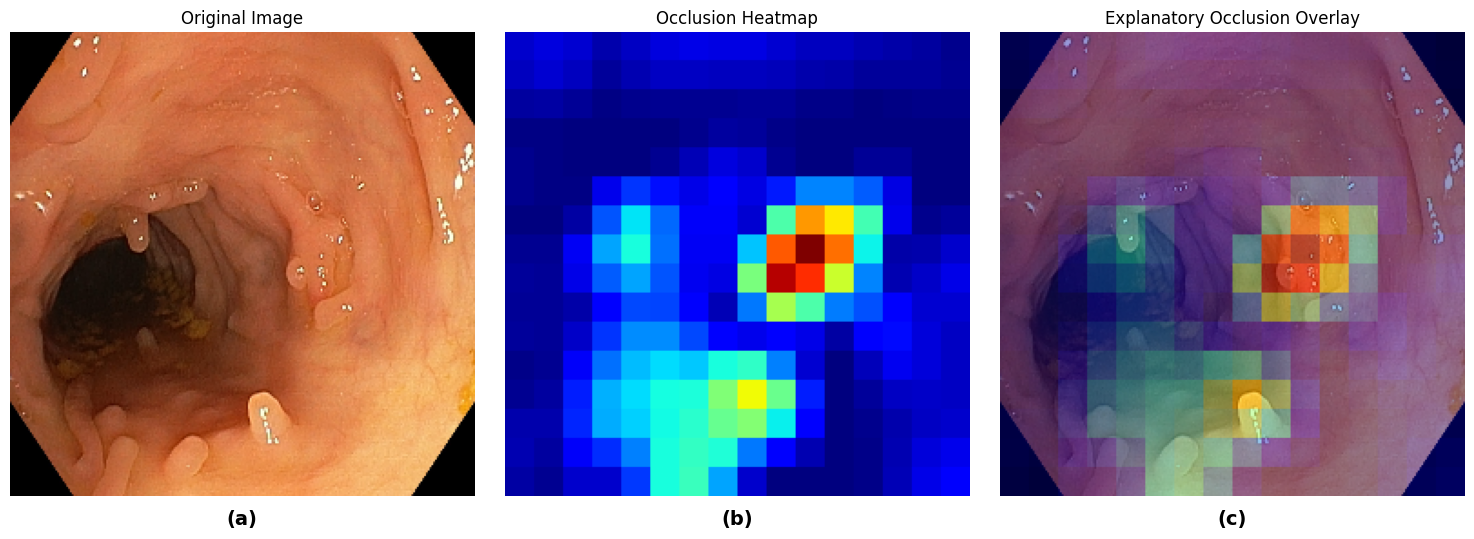

🏆 Visualization compiled and saved cleanly at: ./occlusion_output/155OLCV1_100H0010_occlusion.png


'\noutput_png = generate_feature_map(\n    image_path=IMAGE,\n    model_path=MODEL,\n    target_layer_name=\'clf_pd_cnn\',\n    output_dir="./feature_map_outputs"\n);\ngenerate_waterfall_plot(\n    image_path=IMAGE,\n    model_path=MODEL,\n    elm_artifact_path=ELM_ARTIFACT_PATH,\n    output_png="shap_waterfall_sample_1.png"\n)\ngenerate_single_image_segmentation(\n        model_path=MODEL_PATH,\n        image_path=IMAGE\n);\nprobability, shap_vals = generate_shap_explanation(\n    image_path=IMAGE,\n    model_path=MODEL_PATH,\n    elm_artifact_path=ELM_ARTIFACT_PATH,\n    output_png="shap_image_explanation_pos1.png",\n    max_evals=300\n)\n'

In [47]:
MODEL = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
IMAGE =  "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/155OLCV1_100H0010.jpg"
ELM_ARTIFACT_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/elm_artifacts.npz"
#analyze_score_cam(image_path=IMAGE, model_path=MODEL)
analyze_occlusion_sensitivity(image_path=IMAGE, model_path=MODEL)


"""
output_png = generate_feature_map(
    image_path=IMAGE,
    model_path=MODEL,
    target_layer_name='clf_pd_cnn',
    output_dir="./feature_map_outputs"
);
generate_waterfall_plot(
    image_path=IMAGE,
    model_path=MODEL,
    elm_artifact_path=ELM_ARTIFACT_PATH,
    output_png="shap_waterfall_sample_1.png"
)
generate_single_image_segmentation(
        model_path=MODEL_PATH,
        image_path=IMAGE
);
probability, shap_vals = generate_shap_explanation(
    image_path=IMAGE,
    model_path=MODEL_PATH,
    elm_artifact_path=ELM_ARTIFACT_PATH,
    output_png="shap_image_explanation_pos1.png",
    max_evals=300
)
"""

# Report Profiling

POLYP DETECTION & EXPLAINABILITY REPORT — GENERATING
Loading Y-Net model...
Running classification (ELM ensemble) for detection summary...
Computing segmentation mask & overlay...
Computing feature map...
Computing Score-CAM...
Computing occlusion sensitivity (this may take a moment)...
Computing SHAP explanation (classification head)...
Assembling composite report figure...


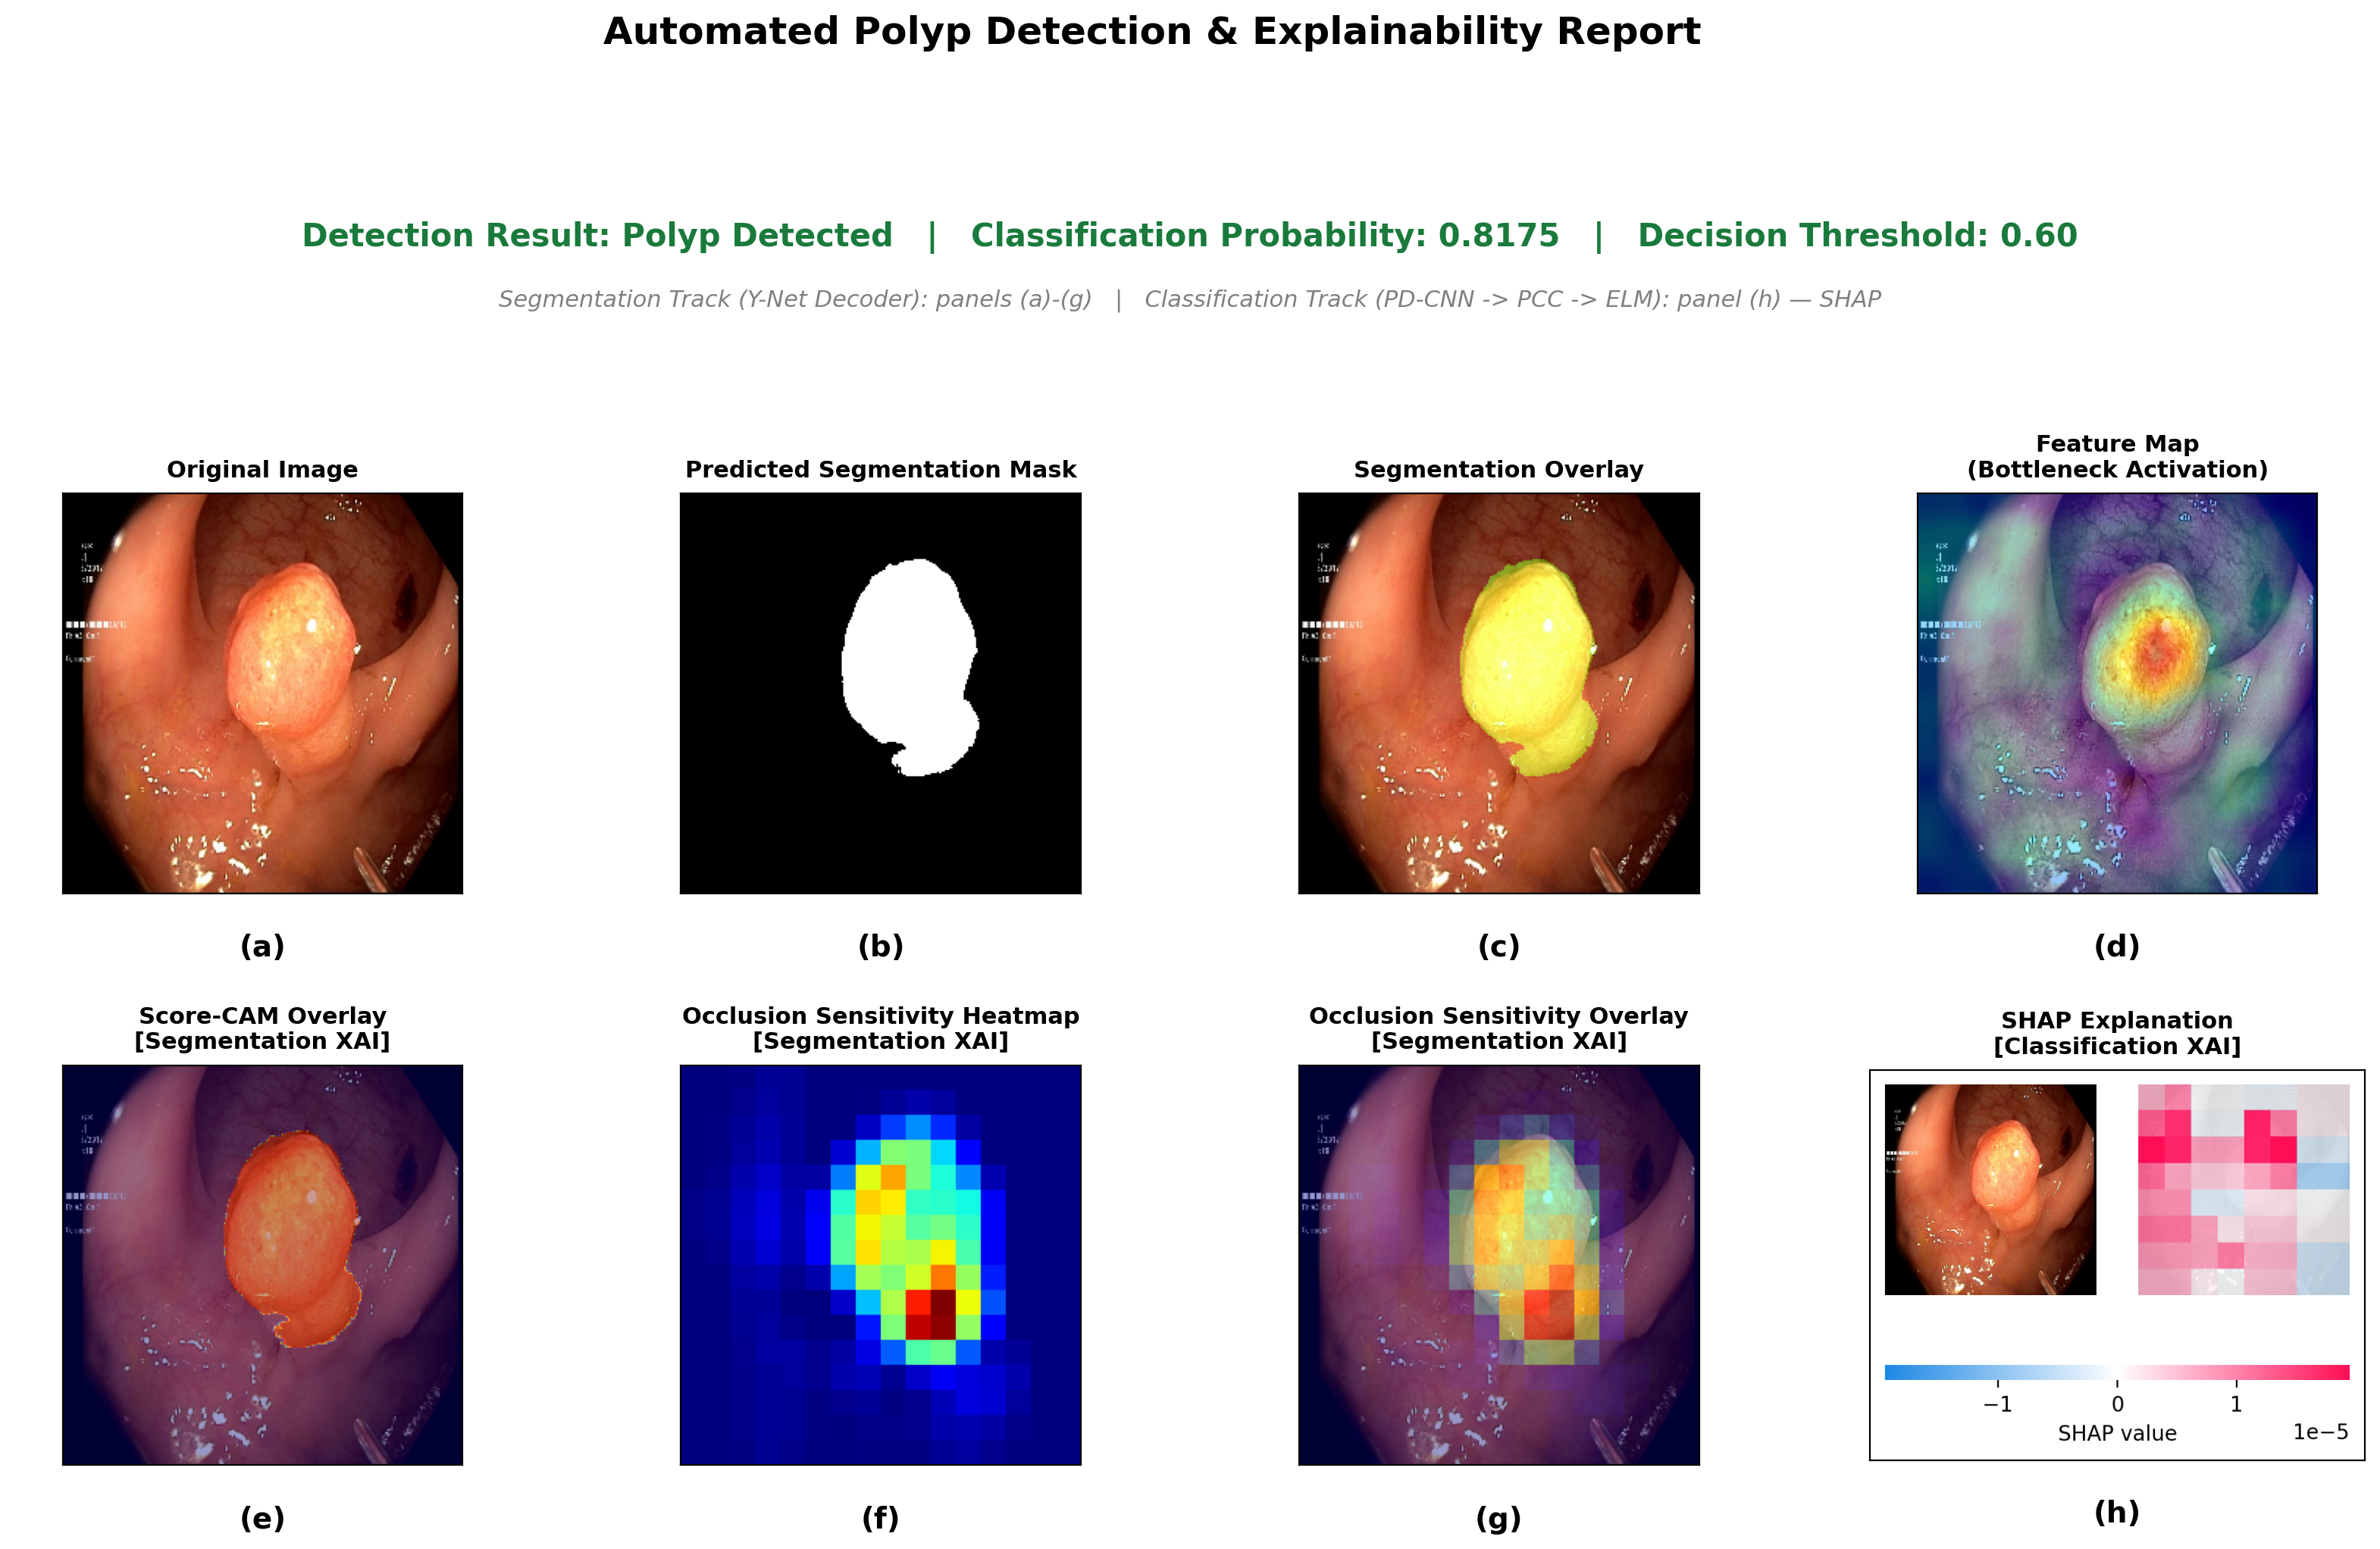

Report saved to: ./polyp_medical_report.png


In [8]:
"""
generate_medical_report.py
============================================================
Unified Polyp Detection & Explainability Report Generator
------------------------------------------------------------
Combines the following analysis modules into ONE composite
report image (single figure, grid layout, labeled a-h):

    Segmentation Track (Y-Net segmentation head):
        (a) Original Image
        (b) Predicted Segmentation Mask
        (c) Segmentation Overlay
        (d) Feature Map (Bottleneck Activation)
        (e) Score-CAM Overlay              [Segmentation XAI]
        (f) Occlusion Sensitivity Heatmap  [Segmentation XAI]
        (g) Occlusion Sensitivity Overlay  [Segmentation XAI]

    Classification Track (PD-CNN -> PCC -> ELM head):
        (h) SHAP Explanation               [Classification XAI]

    Plus a Detection Summary banner: predicted probability,
    binary label, and decision threshold.

NOTE: SHAP is the ONLY explainability method applied to the
CLASSIFICATION head. Every other visualization (Feature Map,
Score-CAM, Occlusion Heatmap/Overlay) explains the
SEGMENTATION head.
============================================================
"""

import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import shap


# ============================================================
# 1. Custom Layer (required for Keras to deserialize the model)
# ============================================================
@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    """Self outer-product Pairwise Correlation Coefficient (PCC) layer."""

    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        epsilon = 1e-8
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(
            tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1)
        )
        return tf.keras.layers.Flatten()(pcc_matrix)

    def get_config(self):
        return super().get_config()


# ============================================================
# 2. Shared Preprocessing Pipeline
# ============================================================
def _preprocess_image(image_path, img_size=256):
    """CLAHE-enhanced + sharpened preprocessing (matches training pipeline)."""
    raw_bgr = cv2.imread(image_path)
    if raw_bgr is None:
        raise ValueError(f"cv2 could not read image: {image_path}")

    img_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (img_size, img_size))

    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    limg = cv2.merge((cl, a_channel, b_channel))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

    median_blur = cv2.medianBlur(enhanced_img, 3)
    sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)

    normalized_tensor = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)
    return img_res, sharpened, normalized_tensor


# ============================================================
# 3. ELM Classification Pipeline (loads .npz artifact)
# ============================================================
def _load_elm_pipeline(elm_artifact_path):
    elm = np.load(elm_artifact_path, allow_pickle=True)
    selector_support = elm["selector_support"]
    scaler_center = elm["scaler_center_"]
    scaler_scale = elm["scaler_scale_"]
    W_input_all = elm["W_input"]
    b_input_all = elm["b_input"]
    W_out_all = elm["ensemble_weights"]

    if selector_support.dtype == bool:
        selected_indices = np.where(selector_support)[0]
    else:
        selected_indices = selector_support.astype(int)

    b_input_vec = b_input_all.reshape(1, -1)
    lambda_outputs = W_out_all.reshape(W_out_all.shape[0], -1, 1)
    ensemble = [(W_input_all, b_input_vec, w_out) for w_out in lambda_outputs]

    return selected_indices, scaler_center, scaler_scale, ensemble


def _elm_predict(feats_scaled, ensemble):
    scores = []
    for W_input, b_input, W_out in ensemble:
        H = np.tanh(np.dot(feats_scaled, W_input) + b_input)
        raw_score = np.dot(H, W_out)
        scores.append(raw_score)
    raw_output = np.mean(scores, axis=0).flatten()
    # Sigmoid দিয়ে (0,1) range-এ map করা
    calibrated_prob = 1 / (1 + np.exp(-raw_output))
    return calibrated_prob


# ============================================================
# 4. Segmentation Mask + Overlay
# ============================================================
def _get_segmentation(seg_model, normalized_tensor, base_rgb, threshold=0.5):
    pred = seg_model(normalized_tensor, training=False)
    pred_mask = pred[0][0].numpy() if isinstance(pred, (list, tuple)) else pred[0].numpy()
    pred_spatial = pred_mask[:, :, 0] if pred_mask.ndim == 3 else pred_mask
    pred_bin = (pred_spatial > threshold).astype(np.uint8) * 255

    overlay_img = base_rgb.copy()
    green_mask = np.zeros_like(base_rgb)
    green_mask[:, :, 1] = pred_bin
    cv2.addWeighted(green_mask, 0.4, overlay_img, 1.0, 0, overlay_img)

    return pred_bin, overlay_img


# ============================================================
# 5. Feature Map (Bottleneck Activation)
# ============================================================
def _get_feature_map(model, normalized_tensor, base_rgb, target_layer_name, img_size):
    feature_model = tf.keras.models.Model(
        inputs=model.input, outputs=model.get_layer(target_layer_name).output
    )
    features = feature_model(normalized_tensor, training=False)
    features = features[0].numpy()

    feature_heatmap = np.mean(features, axis=-1)
    feature_heatmap = np.maximum(feature_heatmap, 0)
    max_val = np.max(feature_heatmap)
    if max_val > 0:
        feature_heatmap = np.where(feature_heatmap > (0.1 * max_val), feature_heatmap, 0.0)
        feature_heatmap = feature_heatmap / np.max(feature_heatmap)

    heatmap_resized = cv2.resize(feature_heatmap, (img_size, img_size))
    color_heatmap = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    color_heatmap_rgb = cv2.cvtColor(color_heatmap, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(base_rgb, 0.6, color_heatmap_rgb, 0.4, 0)
    return overlay


# ============================================================
# 6. Score-CAM (Segmentation XAI)
# ============================================================
def _get_score_cam(model, normalized_tensor, base_rgb, img_size, max_n_features=32):
    target_layer_name = [
        layer.name for layer in model.layers
        if isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.DepthwiseConv2D))
    ][-1]

    score_cam_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(target_layer_name).output, model.output],
    )

    features, predictions = score_cam_model(normalized_tensor, training=False)
    features = features[0].numpy()
    h, w, c = features.shape
    cam = np.zeros((h, w), dtype=np.float32)
    channels_to_process = min(c, max_n_features)

    for i in range(channels_to_process):
        feature_map = features[:, :, i]
        upsampled_map = cv2.resize(feature_map, (img_size, img_size))
        map_min, map_max = upsampled_map.min(), upsampled_map.max()
        if map_max - map_min > 1e-5:
            normalized_map = (upsampled_map - map_min) / (map_max - map_min)
        else:
            normalized_map = upsampled_map
        masked_input = normalized_tensor[0] * np.expand_dims(normalized_map, axis=-1)
        masked_input_tensor = np.expand_dims(masked_input, axis=0)
        g_pred = score_cam_model(masked_input_tensor, training=False)[1]
        score = (
            tf.reduce_mean(g_pred[0]).numpy()
            if isinstance(g_pred, (list, tuple))
            else tf.reduce_mean(g_pred).numpy()
        )
        cam += score * feature_map

    cam = np.maximum(cam, 0)
    if cam.max() > 0:
        cam = cam / cam.max()
    cam = cv2.resize(cam, (img_size, img_size))

    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(base_rgb, 0.6, heatmap_rgb, 0.4, 0)
    return overlay


# ============================================================
# 7. Occlusion Sensitivity (Segmentation XAI)
# ============================================================
def _get_occlusion_sensitivity(model, normalized_tensor, base_rgb, img_size,
                                patch_size=32, stride=16):
    raw_img = normalized_tensor[0]
    h, w, _ = raw_img.shape

    base_preds = model(normalized_tensor, training=False)
    base_mask = base_preds[0][0].numpy() if isinstance(base_preds, (list, tuple)) else base_preds[0].numpy()
    base_score = np.mean(base_mask)

    sensitivity_map = np.zeros((h, w), dtype=np.float32)
    overlap_counts = np.zeros((h, w), dtype=np.float32)

    for y in range(0, h - patch_size + 1, stride):
        for x in range(0, w - patch_size + 1, stride):
            masked_img = np.copy(raw_img)
            masked_img[y:y + patch_size, x:x + patch_size, :] = 0.5
            masked_tensor = np.expand_dims(masked_img, axis=0)

            occ_preds = model(masked_tensor, training=False)
            occ_mask = occ_preds[0][0].numpy() if isinstance(occ_preds, (list, tuple)) else occ_preds[0].numpy()
            occ_score = np.mean(occ_mask)

            score_drop = max(0, base_score - occ_score)
            sensitivity_map[y:y + patch_size, x:x + patch_size] += score_drop
            overlap_counts[y:y + patch_size, x:x + patch_size] += 1.0

    overlap_counts[overlap_counts == 0] = 1.0
    sensitivity_map /= overlap_counts

    map_min, map_max = sensitivity_map.min(), sensitivity_map.max()
    if map_max - map_min > 1e-5:
        sensitivity_map = (sensitivity_map - map_min) / (map_max - map_min)

    heatmap = cv2.applyColorMap(np.uint8(255 * sensitivity_map), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(base_rgb, 0.6, heatmap_rgb, 0.4, 0)

    return sensitivity_map, overlay


# ============================================================
# 8. SHAP (Classification XAI only)
# ============================================================
def _get_shap_panel(image_path, feature_extractor, selected_indices, scaler_center,
                     scaler_scale, ensemble, img_size=256, max_evals=300, batch_size=32):

    def full_pipeline_predict(images_uint8):
        batch = images_uint8.astype(np.float32) / 255.0
        feats = feature_extractor(batch, training=False).numpy()
        feats_sel = feats[:, selected_indices]
        feats_scaled = (feats_sel - scaler_center) / scaler_scale
        return _elm_predict(feats_scaled, ensemble)

    raw_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (img_size, img_size)).astype(np.uint8)

    pred_prob = full_pipeline_predict(np.expand_dims(img_res, axis=0))[0]

    masker = shap.maskers.Image("blur(128,128)", img_res.shape)
    explainer = shap.Explainer(full_pipeline_predict, masker)
    shap_values = explainer(
        np.expand_dims(img_res, axis=0), max_evals=max_evals, batch_size=batch_size
    )

    return pred_prob, shap_values


# ============================================================
# 9. MAIN: Composite Medical Report Generator
# ============================================================
def generate_polyp_medical_report(
    image_path,
    model_path,
    elm_artifact_path,
    output_path="./polyp_medical_report.png",
    img_size=256,
    detection_threshold=0.60,
    seg_mask_threshold=0.5,
    feature_map_layer="clf_pd_cnn",
    shap_max_evals=300,
):
    """
    Generates ONE composite medical-report-style figure combining:
        Segmentation:  mask, overlay, feature map, Score-CAM, occlusion (heatmap + overlay)
        Classification: SHAP explanation
        Detection summary: probability + binary label

    Returns: output_path (str)
    """

    print("=" * 70)
    print("POLYP DETECTION & EXPLAINABILITY REPORT — GENERATING")
    print("=" * 70)

    # ---- 1. Load full multi-output model (segmentation + classification heads) ----
    print("Loading Y-Net model...")
    model = tf.keras.models.load_model(
        model_path, custom_objects={"KerasPCCLayer": KerasPCCLayer}, compile=False
    )

    # Segmentation-only sub-model (first output head)
    seg_model = tf.keras.models.Model(inputs=model.input, outputs=model.outputs[0])

    # Classification feature extractor (PCC layer output, feeds the ELM head)
    feature_extractor = tf.keras.Model(
        inputs=model.input, outputs=model.get_layer("clf_pcc_layer").output
    )

    # ---- 2. Preprocess image ----
    base_rgb, sharpened, normalized_tensor = _preprocess_image(image_path, img_size)

    # ---- 3. Detection (Classification head via ELM ensemble) ----
    print("Running classification (ELM ensemble) for detection summary...")
    selected_indices, scaler_center, scaler_scale, ensemble = _load_elm_pipeline(elm_artifact_path)
    feats = feature_extractor(normalized_tensor, training=False).numpy()
    feats_sel = feats[:, selected_indices]
    feats_scaled = (feats_sel - scaler_center) / scaler_scale
    detection_prob = float(_elm_predict(feats_scaled, ensemble)[0])
    detection_label = "Polyp Detected" if detection_prob >= detection_threshold else "Non-Polyp / Negative"

    # ---- 4. Segmentation mask + overlay ----
    print("Computing segmentation mask & overlay...")
    pred_mask, seg_overlay = _get_segmentation(seg_model, normalized_tensor, base_rgb, seg_mask_threshold)

    # ---- 5. Feature Map (Segmentation XAI) ----
    print("Computing feature map...")
    feature_map_overlay = _get_feature_map(model, normalized_tensor, sharpened, feature_map_layer, img_size)

    # ---- 6. Score-CAM (Segmentation XAI) ----
    print("Computing Score-CAM...")
    score_cam_overlay = _get_score_cam(seg_model, normalized_tensor, base_rgb, img_size)

    # ---- 7. Occlusion Sensitivity (Segmentation XAI) ----
    print("Computing occlusion sensitivity (this may take a moment)...")
    occ_heatmap, occ_overlay = _get_occlusion_sensitivity(seg_model, normalized_tensor, base_rgb, img_size)

    # ---- 8. SHAP (Classification XAI ONLY) ----
    print("Computing SHAP explanation (classification head)...")
    _, shap_values = _get_shap_panel(
        image_path, feature_extractor, selected_indices, scaler_center,
        scaler_scale, ensemble, img_size=img_size, max_evals=shap_max_evals,
    )

    # ============================================================
    # 10. Assemble Composite Report Figure
    # ============================================================
    print("Assembling composite report figure...")
    # fig = plt.figure(figsize=(18, 9.5), dpi=200)  # height একটু কমালাম যেহেতু gap কমছে
    # gs = gridspec.GridSpec(3, 4, height_ratios=[0.3, 1, 1], hspace=0.15, wspace=0.08)
    fig = plt.figure(figsize=(20, 11), dpi=200)
    gs = gridspec.GridSpec(3, 4, height_ratios=[0.35, 1, 1], hspace=0.55, wspace=0.25)
    # gs = gridspec.GridSpec(3, 4, height_ratios=[0.35, 1, 1], hspace=0.15, wspace=0.08)
    # ---- Title + Detection Summary Banner ----
    fig.suptitle("Automated Polyp Detection & Explainability Report",
                 fontsize=18, fontweight="bold", y=0.98)

    ax_summary = fig.add_subplot(gs[0, :])
    ax_summary.axis("off")
    summary_color = "#1a7a3c" if detection_label == "Polyp Detected" else "#8a1a1a"
    ax_summary.text(
        0.5, 0.6,
        f"Detection Result: {detection_label}   |   "
        f"Classification Probability: {detection_prob:.4f}   |   "
        f"Decision Threshold: {detection_threshold:.2f}",
        ha="center", va="center", fontsize=15, fontweight="bold", color=summary_color,
        transform=ax_summary.transAxes,
    )
    ax_summary.text(
        0.5, 0.15,
        "Segmentation Track (Y-Net Decoder): panels (a)-(g)   |   "
        "Classification Track (PD-CNN -> PCC -> ELM): panel (h) — SHAP",
        ha="center", va="center", fontsize=11, style="italic", color="gray",
        transform=ax_summary.transAxes,
    )

    panels = [
        (base_rgb, "Original Image", "(a)", "gray" if False else None, False),
        (pred_mask, "Predicted Segmentation Mask", "(b)", "gray", True),
        (seg_overlay, "Segmentation Overlay", "(c)", None, False),
        (feature_map_overlay, "Feature Map\n(Bottleneck Activation)", "(d)", None, False),
        (score_cam_overlay, "Score-CAM Overlay\n[Segmentation XAI]", "(e)", None, False),
        (occ_heatmap, "Occlusion Sensitivity Heatmap\n[Segmentation XAI]", "(f)", "jet", True),
        (occ_overlay, "Occlusion Sensitivity Overlay\n[Segmentation XAI]", "(g)", None, False),
    ]

    positions = [(1, 0), (1, 1), (1, 2), (1, 3), (2, 0), (2, 1), (2, 2)]

    for (img_data, title, label, cmap, is_gray), (row, col) in zip(panels, positions):
        ax = fig.add_subplot(gs[row, col])
        if cmap == "gray":
            ax.imshow(img_data, cmap="gray")
        elif cmap == "jet":
            ax.imshow(img_data, cmap="jet")
        else:
            ax.imshow(img_data)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
        ax.text(
            0.5, -0.10, label, transform=ax.transAxes,
            fontsize=14, fontweight="bold", ha="center", va="top",
        )

    # ---- SHAP panel (h) — rendered via shap's own image_plot into subplot slot ----
    ax_shap = fig.add_subplot(gs[2, 3])
    ax_shap.set_title("SHAP Explanation\n[Classification XAI]", fontsize=11, fontweight="bold", pad=8)

    # shap.image_plot cannot target an arbitrary axis directly, so render it
    # separately and embed as an image into the composite figure.
    tmp_shap_path = "_tmp_shap_panel.png"
    shap.image_plot(shap_values, show=False)
    plt.gcf().set_size_inches(4, 4)
    plt.savefig(tmp_shap_path, dpi=200, bbox_inches="tight")
    plt.close()  # closes the temporary shap figure, NOT the main report figure

    shap_img = cv2.cvtColor(cv2.imread(tmp_shap_path), cv2.COLOR_BGR2RGB)
    ax_shap.imshow(shap_img)
    ax_shap.set_xticks([])
    ax_shap.set_yticks([])
    ax_shap.text(
        0.5, -0.10, "(h)", transform=ax_shap.transAxes,
        fontsize=14, fontweight="bold", ha="center", va="top",
    )
    os.remove(tmp_shap_path)

    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("=" * 70)
    print(f"Report saved to: {output_path}")
    print("=" * 70)

    return output_path


# ============================================================
# Example usage
# ============================================================
if __name__ == "__main__":
    MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
    ELM_ARTIFACT_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/elm_artifacts.npz"
    IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001304.jpg"

    generate_polyp_medical_report(
        image_path=IMAGE_PATH,
        model_path=MODEL_PATH,
        elm_artifact_path=ELM_ARTIFACT_PATH,
        output_path="./polyp_medical_report.png",
    )

POLYP DETECTION & EXPLAINABILITY REPORT — GENERATING
Loading Y-Net model...
Running classification (ELM ensemble) for detection summary...
Computing segmentation mask & overlay...
Classifying polyp size from segmentation mask...
Computing feature map...
Computing Score-CAM...
Computing occlusion sensitivity (this may take a moment)...
Computing SHAP explanation (classification head)...
Assembling composite report figure...


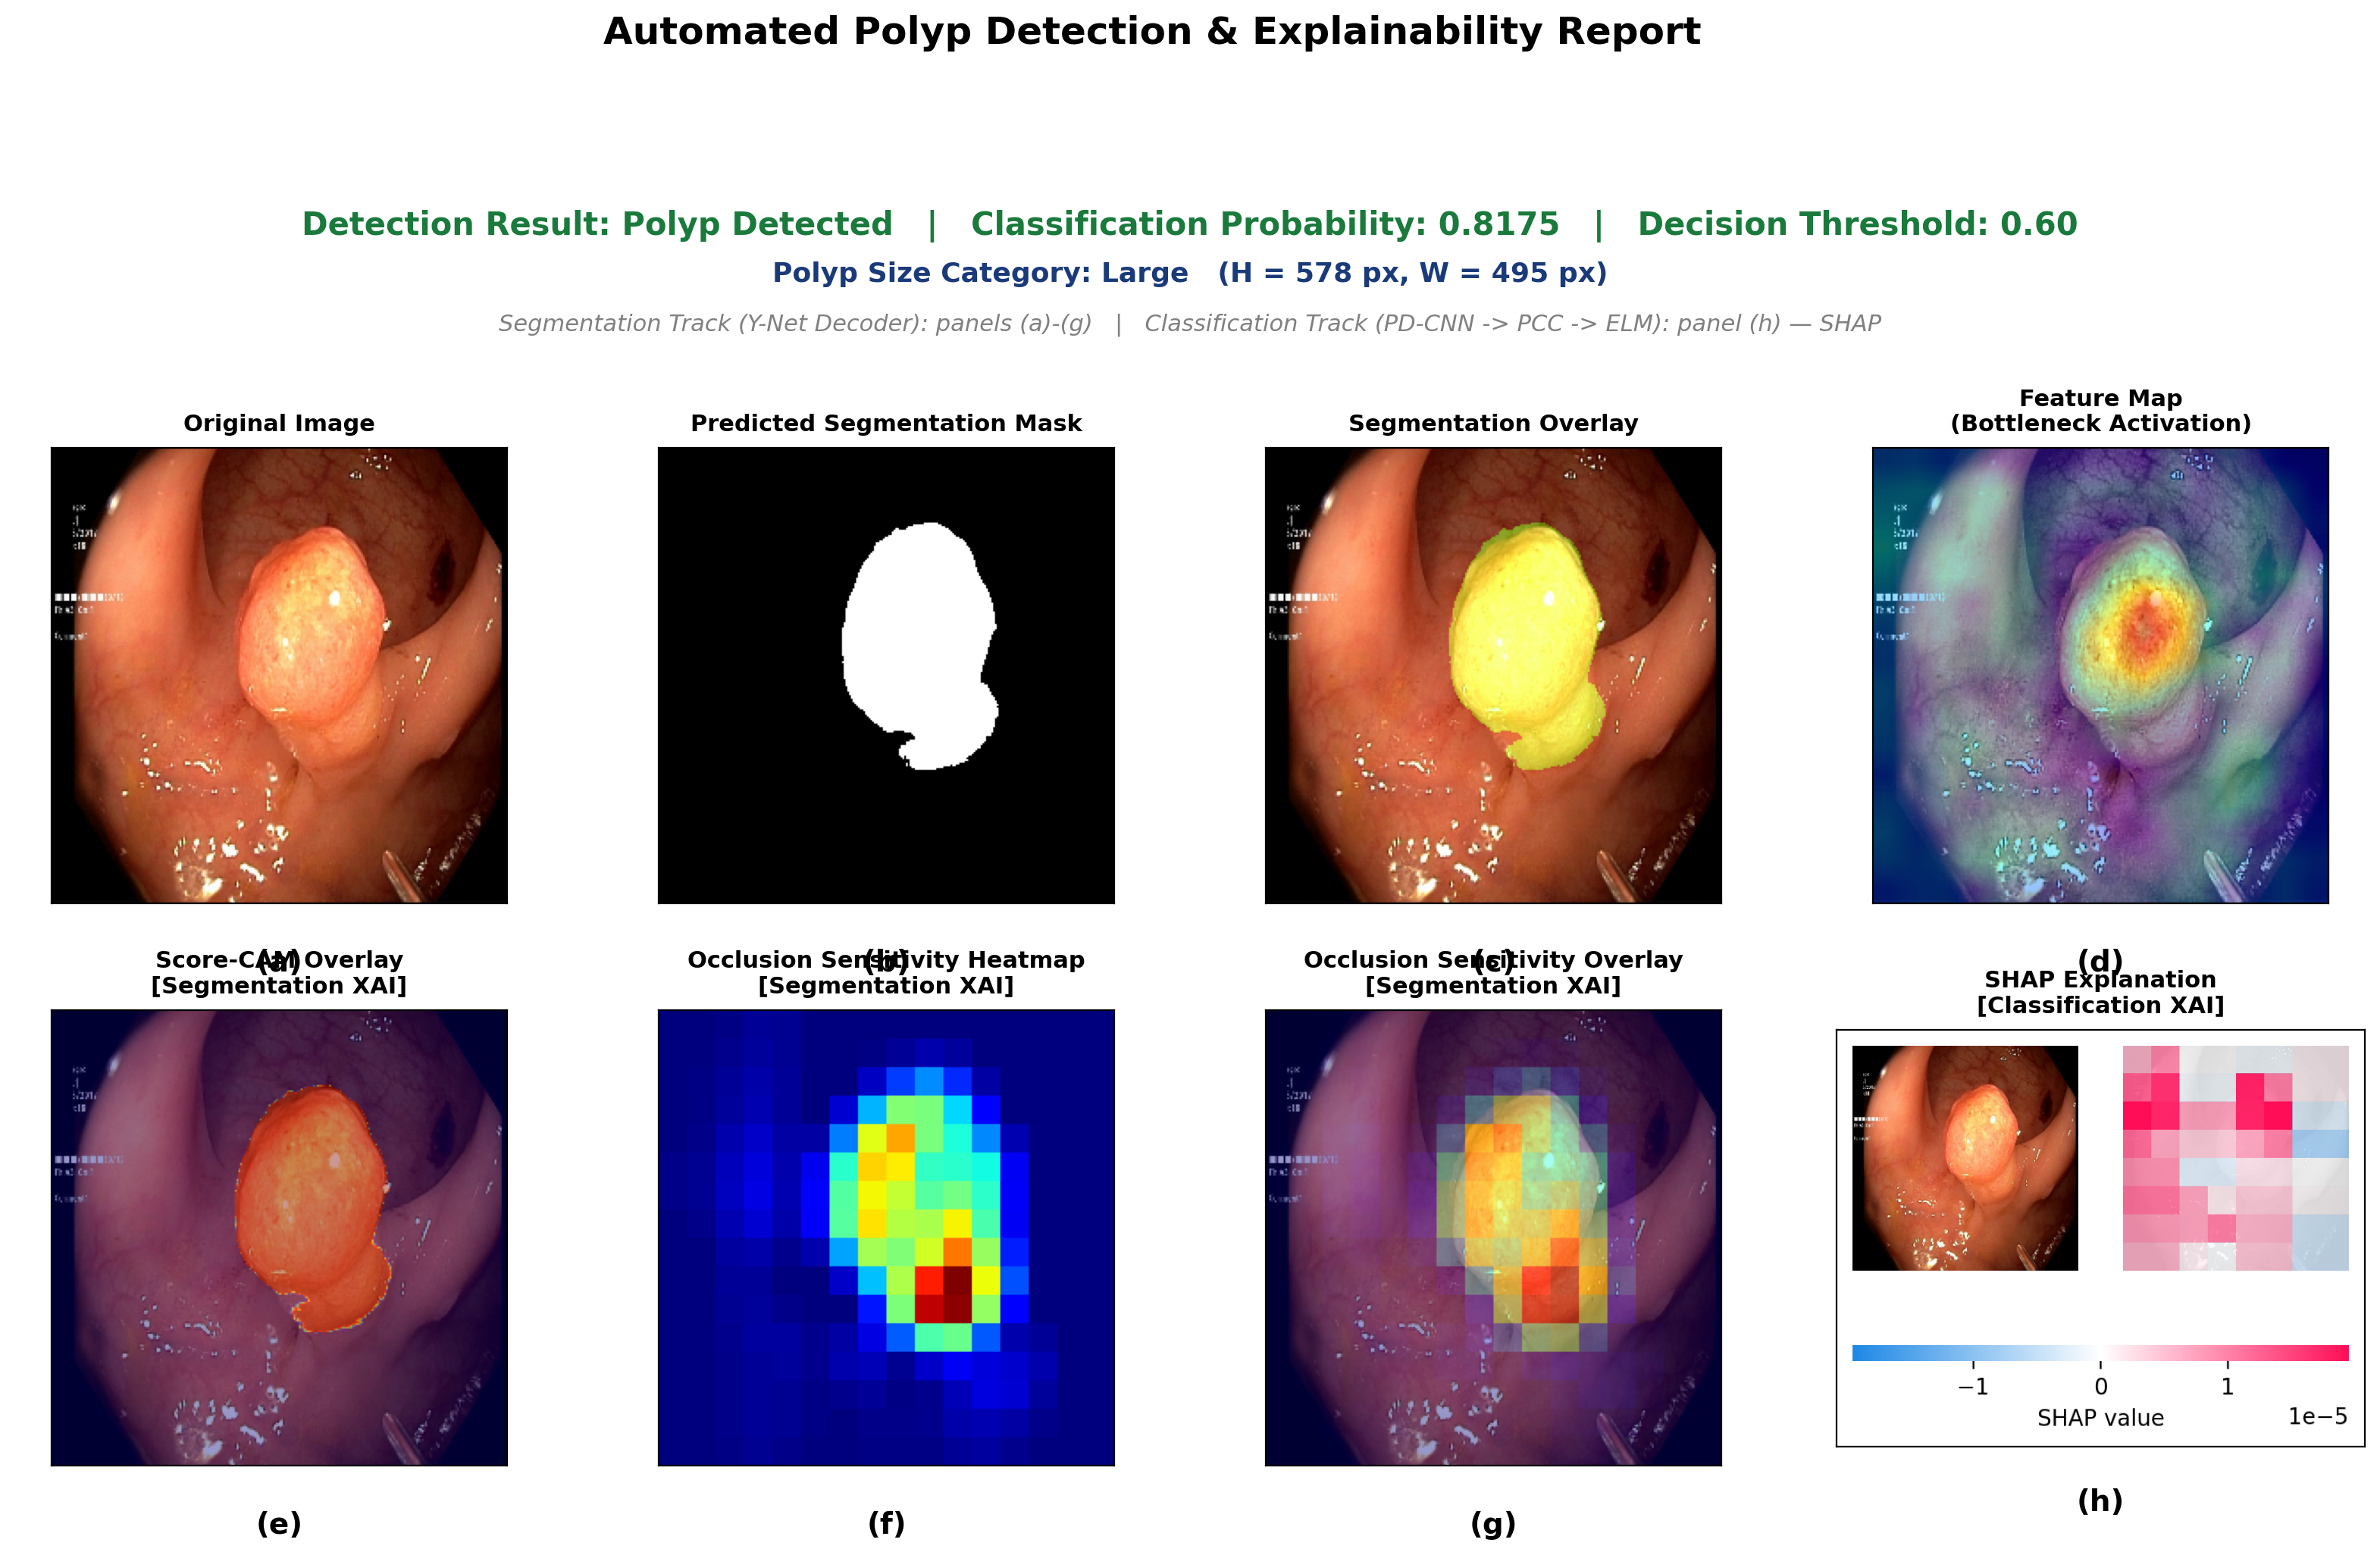

Report saved to: ./polyp_medical_report.png


In [11]:
"""
generate_medical_report.py
============================================================
Unified Polyp Detection & Explainability Report Generator
------------------------------------------------------------
Combines the following analysis modules into ONE composite
report image (single figure, grid layout, labeled a-h):

    Segmentation Track (Y-Net segmentation head):
        (a) Original Image
        (b) Predicted Segmentation Mask
        (c) Segmentation Overlay
        (d) Feature Map (Bottleneck Activation)
        (e) Score-CAM Overlay              [Segmentation XAI]
        (f) Occlusion Sensitivity Heatmap  [Segmentation XAI]
        (g) Occlusion Sensitivity Overlay  [Segmentation XAI]

    Classification Track (PD-CNN -> PCC -> ELM head):
        (h) SHAP Explanation               [Classification XAI]

    Plus a Detection Summary banner: predicted probability,
    binary label, and decision threshold.

NOTE: SHAP is the ONLY explainability method applied to the
CLASSIFICATION head. Every other visualization (Feature Map,
Score-CAM, Occlusion Heatmap/Overlay) explains the
SEGMENTATION head.
============================================================
"""

import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import shap


# ============================================================
# 1. Custom Layer (required for Keras to deserialize the model)
# ============================================================
@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    """Self outer-product Pairwise Correlation Coefficient (PCC) layer."""

    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        epsilon = 1e-8
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(
            tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1)
        )
        return tf.keras.layers.Flatten()(pcc_matrix)

    def get_config(self):
        return super().get_config()


# ============================================================
# 2. Shared Preprocessing Pipeline
# ============================================================
def _preprocess_image(image_path, img_size=256):
    """CLAHE-enhanced + sharpened preprocessing (matches training pipeline)."""
    raw_bgr = cv2.imread(image_path)
    if raw_bgr is None:
        raise ValueError(f"cv2 could not read image: {image_path}")

    img_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (img_size, img_size))

    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    limg = cv2.merge((cl, a_channel, b_channel))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

    median_blur = cv2.medianBlur(enhanced_img, 3)
    sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)

    normalized_tensor = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)
    return img_res, sharpened, normalized_tensor


# ============================================================
# 3. ELM Classification Pipeline (loads .npz artifact)
# ============================================================
def _load_elm_pipeline(elm_artifact_path):
    elm = np.load(elm_artifact_path, allow_pickle=True)
    selector_support = elm["selector_support"]
    scaler_center = elm["scaler_center_"]
    scaler_scale = elm["scaler_scale_"]
    W_input_all = elm["W_input"]
    b_input_all = elm["b_input"]
    W_out_all = elm["ensemble_weights"]

    if selector_support.dtype == bool:
        selected_indices = np.where(selector_support)[0]
    else:
        selected_indices = selector_support.astype(int)

    b_input_vec = b_input_all.reshape(1, -1)
    lambda_outputs = W_out_all.reshape(W_out_all.shape[0], -1, 1)
    ensemble = [(W_input_all, b_input_vec, w_out) for w_out in lambda_outputs]

    return selected_indices, scaler_center, scaler_scale, ensemble


def _elm_predict(feats_scaled, ensemble):
    scores = []
    for W_input, b_input, W_out in ensemble:
        H = np.tanh(np.dot(feats_scaled, W_input) + b_input)
        raw_score = np.dot(H, W_out)
        scores.append(raw_score)
    raw_output = np.mean(scores, axis=0).flatten()
    # Sigmoid দিয়ে (0,1) range-এ map করা
    calibrated_prob = 1 / (1 + np.exp(-raw_output))
    return calibrated_prob

# ============================================================
# 4. Segmentation Mask + Overlay
# ============================================================
def _get_segmentation(seg_model, normalized_tensor, base_rgb, threshold=0.5):
    pred = seg_model(normalized_tensor, training=False)
    pred_mask = pred[0][0].numpy() if isinstance(pred, (list, tuple)) else pred[0].numpy()
    pred_spatial = pred_mask[:, :, 0] if pred_mask.ndim == 3 else pred_mask
    pred_bin = (pred_spatial > threshold).astype(np.uint8) * 255

    overlay_img = base_rgb.copy()
    green_mask = np.zeros_like(base_rgb)
    green_mask[:, :, 1] = pred_bin
    cv2.addWeighted(green_mask, 0.4, overlay_img, 1.0, 0, overlay_img)

    return pred_bin, overlay_img


# ============================================================
# 5. Feature Map (Bottleneck Activation)
# ============================================================
def _get_feature_map(model, normalized_tensor, base_rgb, target_layer_name, img_size):
    feature_model = tf.keras.models.Model(
        inputs=model.input, outputs=model.get_layer(target_layer_name).output
    )
    features = feature_model(normalized_tensor, training=False)
    features = features[0].numpy()

    feature_heatmap = np.mean(features, axis=-1)
    feature_heatmap = np.maximum(feature_heatmap, 0)
    max_val = np.max(feature_heatmap)
    if max_val > 0:
        feature_heatmap = np.where(feature_heatmap > (0.1 * max_val), feature_heatmap, 0.0)
        feature_heatmap = feature_heatmap / np.max(feature_heatmap)

    heatmap_resized = cv2.resize(feature_heatmap, (img_size, img_size))
    color_heatmap = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    color_heatmap_rgb = cv2.cvtColor(color_heatmap, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(base_rgb, 0.6, color_heatmap_rgb, 0.4, 0)
    return overlay


# ============================================================
# 5b. Polyp Size Classification (from segmentation mask)
# ============================================================
def _classify_polyp_size(pred_mask, orig_shape, img_size):
    """
    Determines polyp size category from the predicted segmentation mask.

    Size categories (measured on ORIGINAL image resolution, in pixels):
        Small  : H <= 100  and W <= 100
        Medium : 100 < H <= 200  and  100 < W <= 200
        Large  : H >= 200  and W >= 200

    Uses the largest connected component in the binary mask as the
    polyp region, then takes its bounding-box height/width, rescaled
    from the model's working resolution (img_size) back to the
    original image resolution.

    Returns: dict with keys:
        label        -> "Small" | "Medium" | "Large" | "No Polyp Detected"
        height_px    -> int (bounding-box height, original resolution)
        width_px     -> int (bounding-box width, original resolution)
        bbox         -> (x, y, w, h) in mask-resolution coordinates, or None
    """
    orig_h, orig_w = orig_shape[:2]
    scale_y = orig_h / img_size
    scale_x = orig_w / img_size

    binary_mask = (pred_mask > 0).astype(np.uint8)

    num_labels, labels_im, stats, _ = cv2.connectedComponentsWithStats(
        binary_mask, connectivity=8
    )

    if num_labels <= 1:
        # Only the background component was found -> no polyp region.
        return {"label": "No Polyp Detected", "height_px": 0, "width_px": 0, "bbox": None}

    # Ignore label 0 (background); pick the largest foreground component.
    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    x, y, w, h, area = stats[largest_label]

    # Rescale bounding box dimensions to ORIGINAL image resolution.
    height_px = int(round(h * scale_y))
    width_px = int(round(w * scale_x))

    if height_px <= 100 and width_px <= 100:
        size_label = "Small"
    elif height_px >= 200 and width_px >= 200:
        size_label = "Large"
    else:
        size_label = "Medium"

    return {
        "label": size_label,
        "height_px": height_px,
        "width_px": width_px,
        "bbox": (x, y, w, h),
    }


# ============================================================
# 6. Score-CAM (Segmentation XAI)
# ============================================================
def _get_score_cam(model, normalized_tensor, base_rgb, img_size, max_n_features=32):
    target_layer_name = [
        layer.name for layer in model.layers
        if isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.DepthwiseConv2D))
    ][-1]

    score_cam_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(target_layer_name).output, model.output],
    )

    features, predictions = score_cam_model(normalized_tensor, training=False)
    features = features[0].numpy()
    h, w, c = features.shape
    cam = np.zeros((h, w), dtype=np.float32)
    channels_to_process = min(c, max_n_features)

    for i in range(channels_to_process):
        feature_map = features[:, :, i]
        upsampled_map = cv2.resize(feature_map, (img_size, img_size))
        map_min, map_max = upsampled_map.min(), upsampled_map.max()
        if map_max - map_min > 1e-5:
            normalized_map = (upsampled_map - map_min) / (map_max - map_min)
        else:
            normalized_map = upsampled_map
        masked_input = normalized_tensor[0] * np.expand_dims(normalized_map, axis=-1)
        masked_input_tensor = np.expand_dims(masked_input, axis=0)
        g_pred = score_cam_model(masked_input_tensor, training=False)[1]
        score = (
            tf.reduce_mean(g_pred[0]).numpy()
            if isinstance(g_pred, (list, tuple))
            else tf.reduce_mean(g_pred).numpy()
        )
        cam += score * feature_map

    cam = np.maximum(cam, 0)
    if cam.max() > 0:
        cam = cam / cam.max()
    cam = cv2.resize(cam, (img_size, img_size))

    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(base_rgb, 0.6, heatmap_rgb, 0.4, 0)
    return overlay


# ============================================================
# 7. Occlusion Sensitivity (Segmentation XAI)
# ============================================================
def _get_occlusion_sensitivity(model, normalized_tensor, base_rgb, img_size,
                                patch_size=32, stride=16):
    raw_img = normalized_tensor[0]
    h, w, _ = raw_img.shape

    base_preds = model(normalized_tensor, training=False)
    base_mask = base_preds[0][0].numpy() if isinstance(base_preds, (list, tuple)) else base_preds[0].numpy()
    base_score = np.mean(base_mask)

    sensitivity_map = np.zeros((h, w), dtype=np.float32)
    overlap_counts = np.zeros((h, w), dtype=np.float32)

    for y in range(0, h - patch_size + 1, stride):
        for x in range(0, w - patch_size + 1, stride):
            masked_img = np.copy(raw_img)
            masked_img[y:y + patch_size, x:x + patch_size, :] = 0.5
            masked_tensor = np.expand_dims(masked_img, axis=0)

            occ_preds = model(masked_tensor, training=False)
            occ_mask = occ_preds[0][0].numpy() if isinstance(occ_preds, (list, tuple)) else occ_preds[0].numpy()
            occ_score = np.mean(occ_mask)

            score_drop = max(0, base_score - occ_score)
            sensitivity_map[y:y + patch_size, x:x + patch_size] += score_drop
            overlap_counts[y:y + patch_size, x:x + patch_size] += 1.0

    overlap_counts[overlap_counts == 0] = 1.0
    sensitivity_map /= overlap_counts

    map_min, map_max = sensitivity_map.min(), sensitivity_map.max()
    if map_max - map_min > 1e-5:
        sensitivity_map = (sensitivity_map - map_min) / (map_max - map_min)

    heatmap = cv2.applyColorMap(np.uint8(255 * sensitivity_map), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(base_rgb, 0.6, heatmap_rgb, 0.4, 0)

    return sensitivity_map, overlay


# ============================================================
# 8. SHAP (Classification XAI only)
# ============================================================
def _get_shap_panel(image_path, feature_extractor, selected_indices, scaler_center,
                     scaler_scale, ensemble, img_size=256, max_evals=300, batch_size=32):

    def full_pipeline_predict(images_uint8):
        batch = images_uint8.astype(np.float32) / 255.0
        feats = feature_extractor(batch, training=False).numpy()
        feats_sel = feats[:, selected_indices]
        feats_scaled = (feats_sel - scaler_center) / scaler_scale
        return _elm_predict(feats_scaled, ensemble)

    raw_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (img_size, img_size)).astype(np.uint8)

    pred_prob = full_pipeline_predict(np.expand_dims(img_res, axis=0))[0]

    masker = shap.maskers.Image("blur(128,128)", img_res.shape)
    explainer = shap.Explainer(full_pipeline_predict, masker)
    shap_values = explainer(
        np.expand_dims(img_res, axis=0), max_evals=max_evals, batch_size=batch_size
    )

    return pred_prob, shap_values


# ============================================================
# 9. MAIN: Composite Medical Report Generator
# ============================================================
def generate_polyp_medical_report(
    image_path,
    model_path,
    elm_artifact_path,
    output_path="./polyp_medical_report.png",
    img_size=256,
    detection_threshold=0.60,
    seg_mask_threshold=0.5,
    feature_map_layer="clf_pd_cnn",
    shap_max_evals=300,
):
    """
    Generates ONE composite medical-report-style figure combining:
        Segmentation:  mask, overlay, feature map, Score-CAM, occlusion (heatmap + overlay)
        Classification: SHAP explanation
        Detection summary: probability + binary label

    Returns: output_path (str)
    """

    print("=" * 70)
    print("POLYP DETECTION & EXPLAINABILITY REPORT — GENERATING")
    print("=" * 70)

    # ---- 1. Load full multi-output model (segmentation + classification heads) ----
    print("Loading Y-Net model...")
    model = tf.keras.models.load_model(
        model_path, custom_objects={"KerasPCCLayer": KerasPCCLayer}, compile=False
    )

    # Segmentation-only sub-model (first output head)
    seg_model = tf.keras.models.Model(inputs=model.input, outputs=model.outputs[0])

    # Classification feature extractor (PCC layer output, feeds the ELM head)
    feature_extractor = tf.keras.Model(
        inputs=model.input, outputs=model.get_layer("clf_pcc_layer").output
    )

    # ---- 2. Preprocess image ----
    base_rgb, sharpened, normalized_tensor = _preprocess_image(image_path, img_size)

    # ---- 3. Detection (Classification head via ELM ensemble) ----
    print("Running classification (ELM ensemble) for detection summary...")
    selected_indices, scaler_center, scaler_scale, ensemble = _load_elm_pipeline(elm_artifact_path)
    feats = feature_extractor(normalized_tensor, training=False).numpy()
    feats_sel = feats[:, selected_indices]
    feats_scaled = (feats_sel - scaler_center) / scaler_scale
    detection_prob = float(_elm_predict(feats_scaled, ensemble)[0])
    detection_label = "Polyp Detected" if detection_prob >= detection_threshold else "Non-Polyp / Negative"

    # ---- 4. Segmentation mask + overlay ----
    print("Computing segmentation mask & overlay...")
    pred_mask, seg_overlay = _get_segmentation(seg_model, normalized_tensor, base_rgb, seg_mask_threshold)

    # ---- 4b. Polyp size classification (Small / Medium / Large) ----
    print("Classifying polyp size from segmentation mask...")
    orig_shape = cv2.imread(image_path).shape  # original resolution, for real-world pixel sizing
    size_info = _classify_polyp_size(pred_mask, orig_shape, img_size)

    # ---- 5. Feature Map (Segmentation XAI) ----
    print("Computing feature map...")
    feature_map_overlay = _get_feature_map(model, normalized_tensor, sharpened, feature_map_layer, img_size)

    # ---- 6. Score-CAM (Segmentation XAI) ----
    print("Computing Score-CAM...")
    score_cam_overlay = _get_score_cam(seg_model, normalized_tensor, base_rgb, img_size)

    # ---- 7. Occlusion Sensitivity (Segmentation XAI) ----
    print("Computing occlusion sensitivity (this may take a moment)...")
    occ_heatmap, occ_overlay = _get_occlusion_sensitivity(seg_model, normalized_tensor, base_rgb, img_size)

    # ---- 8. SHAP (Classification XAI ONLY) ----
    print("Computing SHAP explanation (classification head)...")
    _, shap_values = _get_shap_panel(
        image_path, feature_extractor, selected_indices, scaler_center,
        scaler_scale, ensemble, img_size=img_size, max_evals=shap_max_evals,
    )

    # ============================================================
    # 10. Assemble Composite Report Figure
    # ============================================================
    print("Assembling composite report figure...")

    fig = plt.figure(figsize=(20, 11), dpi=200)
    gs = gridspec.GridSpec(3, 4, height_ratios=[0.35, 1, 1], hspace=0.30, wspace=0.15)
    #fig = plt.figure(figsize=(20, 11), dpi=200)
    #gs = gridspec.GridSpec(3, 4, height_ratios=[0.35, 1, 1], hspace=0.55, wspace=0.25)
    # ---- Title + Detection Summary Banner ----
    fig.suptitle("Automated Polyp Detection & Explainability Report",
                 fontsize=18, fontweight="bold", y=0.98)

    ax_summary = fig.add_subplot(gs[0, :])
    ax_summary.axis("off")
    summary_color = "#1a7a3c" if detection_label == "Polyp Detected" else "#8a1a1a"
    ax_summary.text(
        0.5, 0.72,
        f"Detection Result: {detection_label}   |   "
        f"Classification Probability: {detection_prob:.4f}   |   "
        f"Decision Threshold: {detection_threshold:.2f}",
        ha="center", va="center", fontsize=15, fontweight="bold", color=summary_color,
        transform=ax_summary.transAxes,
    )

    # ---- Polyp size description line ----
    if size_info["label"] == "No Polyp Detected":
        size_line = "Polyp Size: N/A (no segmented region found)"
    else:
        size_line = (
            f"Polyp Size Category: {size_info['label']}   "
            f"(H = {size_info['height_px']} px, W = {size_info['width_px']} px)"
        )
    ax_summary.text(
        0.5, 0.42,
        size_line,
        ha="center", va="center", fontsize=13, fontweight="bold", color="#1a3a7a",
        transform=ax_summary.transAxes,
    )

    ax_summary.text(
        0.5, 0.10,
        "Segmentation Track (Y-Net Decoder): panels (a)-(g)   |   "
        "Classification Track (PD-CNN -> PCC -> ELM): panel (h) — SHAP",
        ha="center", va="center", fontsize=11, style="italic", color="gray",
        transform=ax_summary.transAxes,
    )

    panels = [
        (base_rgb, "Original Image", "(a)", "gray" if False else None, False),
        (pred_mask, "Predicted Segmentation Mask", "(b)", "gray", True),
        (seg_overlay, "Segmentation Overlay", "(c)", None, False),
        (feature_map_overlay, "Feature Map\n(Bottleneck Activation)", "(d)", None, False),
        (score_cam_overlay, "Score-CAM Overlay\n[Segmentation XAI]", "(e)", None, False),
        (occ_heatmap, "Occlusion Sensitivity Heatmap\n[Segmentation XAI]", "(f)", "jet", True),
        (occ_overlay, "Occlusion Sensitivity Overlay\n[Segmentation XAI]", "(g)", None, False),
    ]

    positions = [(1, 0), (1, 1), (1, 2), (1, 3), (2, 0), (2, 1), (2, 2)]

    for (img_data, title, label, cmap, is_gray), (row, col) in zip(panels, positions):
        ax = fig.add_subplot(gs[row, col])
        if cmap == "gray":
            ax.imshow(img_data, cmap="gray")
        elif cmap == "jet":
            ax.imshow(img_data, cmap="jet")
        else:
            ax.imshow(img_data)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
        ax.text(
            0.5, -0.10, label, transform=ax.transAxes,
            fontsize=14, fontweight="bold", ha="center", va="top",
        )

    # ---- SHAP panel (h) — rendered via shap's own image_plot into subplot slot ----
    ax_shap = fig.add_subplot(gs[2, 3])
    ax_shap.set_title("SHAP Explanation\n[Classification XAI]", fontsize=11, fontweight="bold", pad=8)

    # shap.image_plot cannot target an arbitrary axis directly, so render it
    # separately and embed as an image into the composite figure.
    tmp_shap_path = "_tmp_shap_panel.png"
    shap.image_plot(shap_values, show=False)
    plt.gcf().set_size_inches(4, 4)
    plt.savefig(tmp_shap_path, dpi=200, bbox_inches="tight")
    plt.close()  # closes the temporary shap figure, NOT the main report figure

    shap_img = cv2.cvtColor(cv2.imread(tmp_shap_path), cv2.COLOR_BGR2RGB)
    ax_shap.imshow(shap_img)
    ax_shap.set_xticks([])
    ax_shap.set_yticks([])
    ax_shap.text(
        0.5, -0.10, "(h)", transform=ax_shap.transAxes,
        fontsize=14, fontweight="bold", ha="center", va="top",
    )
    os.remove(tmp_shap_path)

    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("=" * 70)
    print(f"Report saved to: {output_path}")
    print("=" * 70)

    return output_path


# ============================================================
# Example usage
# ============================================================
if __name__ == "__main__":
    MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
    ELM_ARTIFACT_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/elm_artifacts.npz"
    IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001304.jpg"

    generate_polyp_medical_report(
        image_path=IMAGE_PATH,
        model_path=MODEL_PATH,
        elm_artifact_path=ELM_ARTIFACT_PATH,
        output_path="./polyp_medical_report.png",
    )

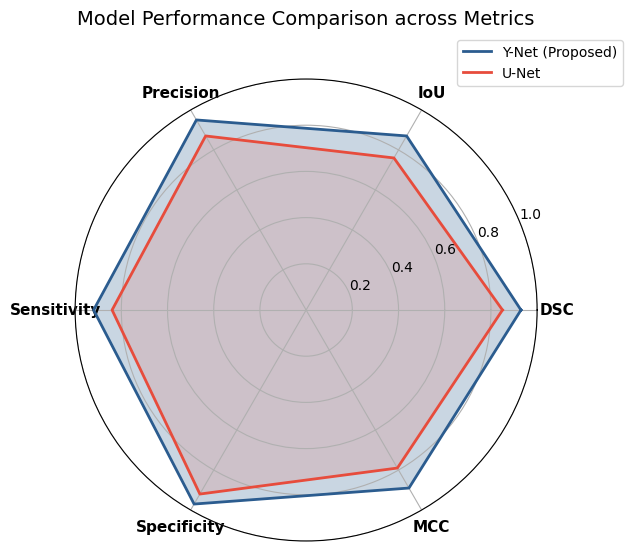

In [12]:
import numpy as np
import matplotlib.pyplot as plt

# ১. মেট্রিক্সের নাম
labels = ['DSC', 'IoU', 'Precision', 'Sensitivity', 'Specificity', 'MCC']
num_vars = len(labels)

# ২. মডেলগুলোর পাওয়া স্কোরের ডেটা (Sample Data)
ynet_scores = [0.93, 0.87, 0.95, 0.92, 0.97, 0.89]  # Proposed Model
unet_scores = [0.85, 0.76, 0.87, 0.84, 0.92, 0.79]  # Benchmark Model

# ৩. বৃত্তের কোণ (Angles) গণনা
angles = np.linspace(0, 2 * np.pi, num_vars, endpoint=False).tolist()

# লুপ শেষ করার জন্য ১ম ভ্যালু আবার শেষে যুক্ত করা
ynet_scores += ynet_scores[:1]
unet_scores += unet_scores[:1]
angles += angles[:1]

# ৪. প্লট তৈরি
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(polar=True))

# Y-Net Plot
ax.plot(angles, ynet_scores, color='#2b5c8f', linewidth=2, label='Y-Net (Proposed)')
ax.fill(angles, ynet_scores, color='#2b5c8f', alpha=0.25)

# UNet Plot
ax.plot(angles, unet_scores, color='#e74c3c', linewidth=2, label='U-Net')
ax.fill(angles, unet_scores, color='#e74c3c', alpha=0.15)

# লেবেল ঠিক করা
ax.set_xticks(angles[:-1])
ax.set_xticklabels(labels, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.0)

plt.title("Model Performance Comparison across Metrics", size=14, y=1.1)
plt.legend(loc='upper right', bbox_to_anchor=(1.2, 1.1))
plt.show()

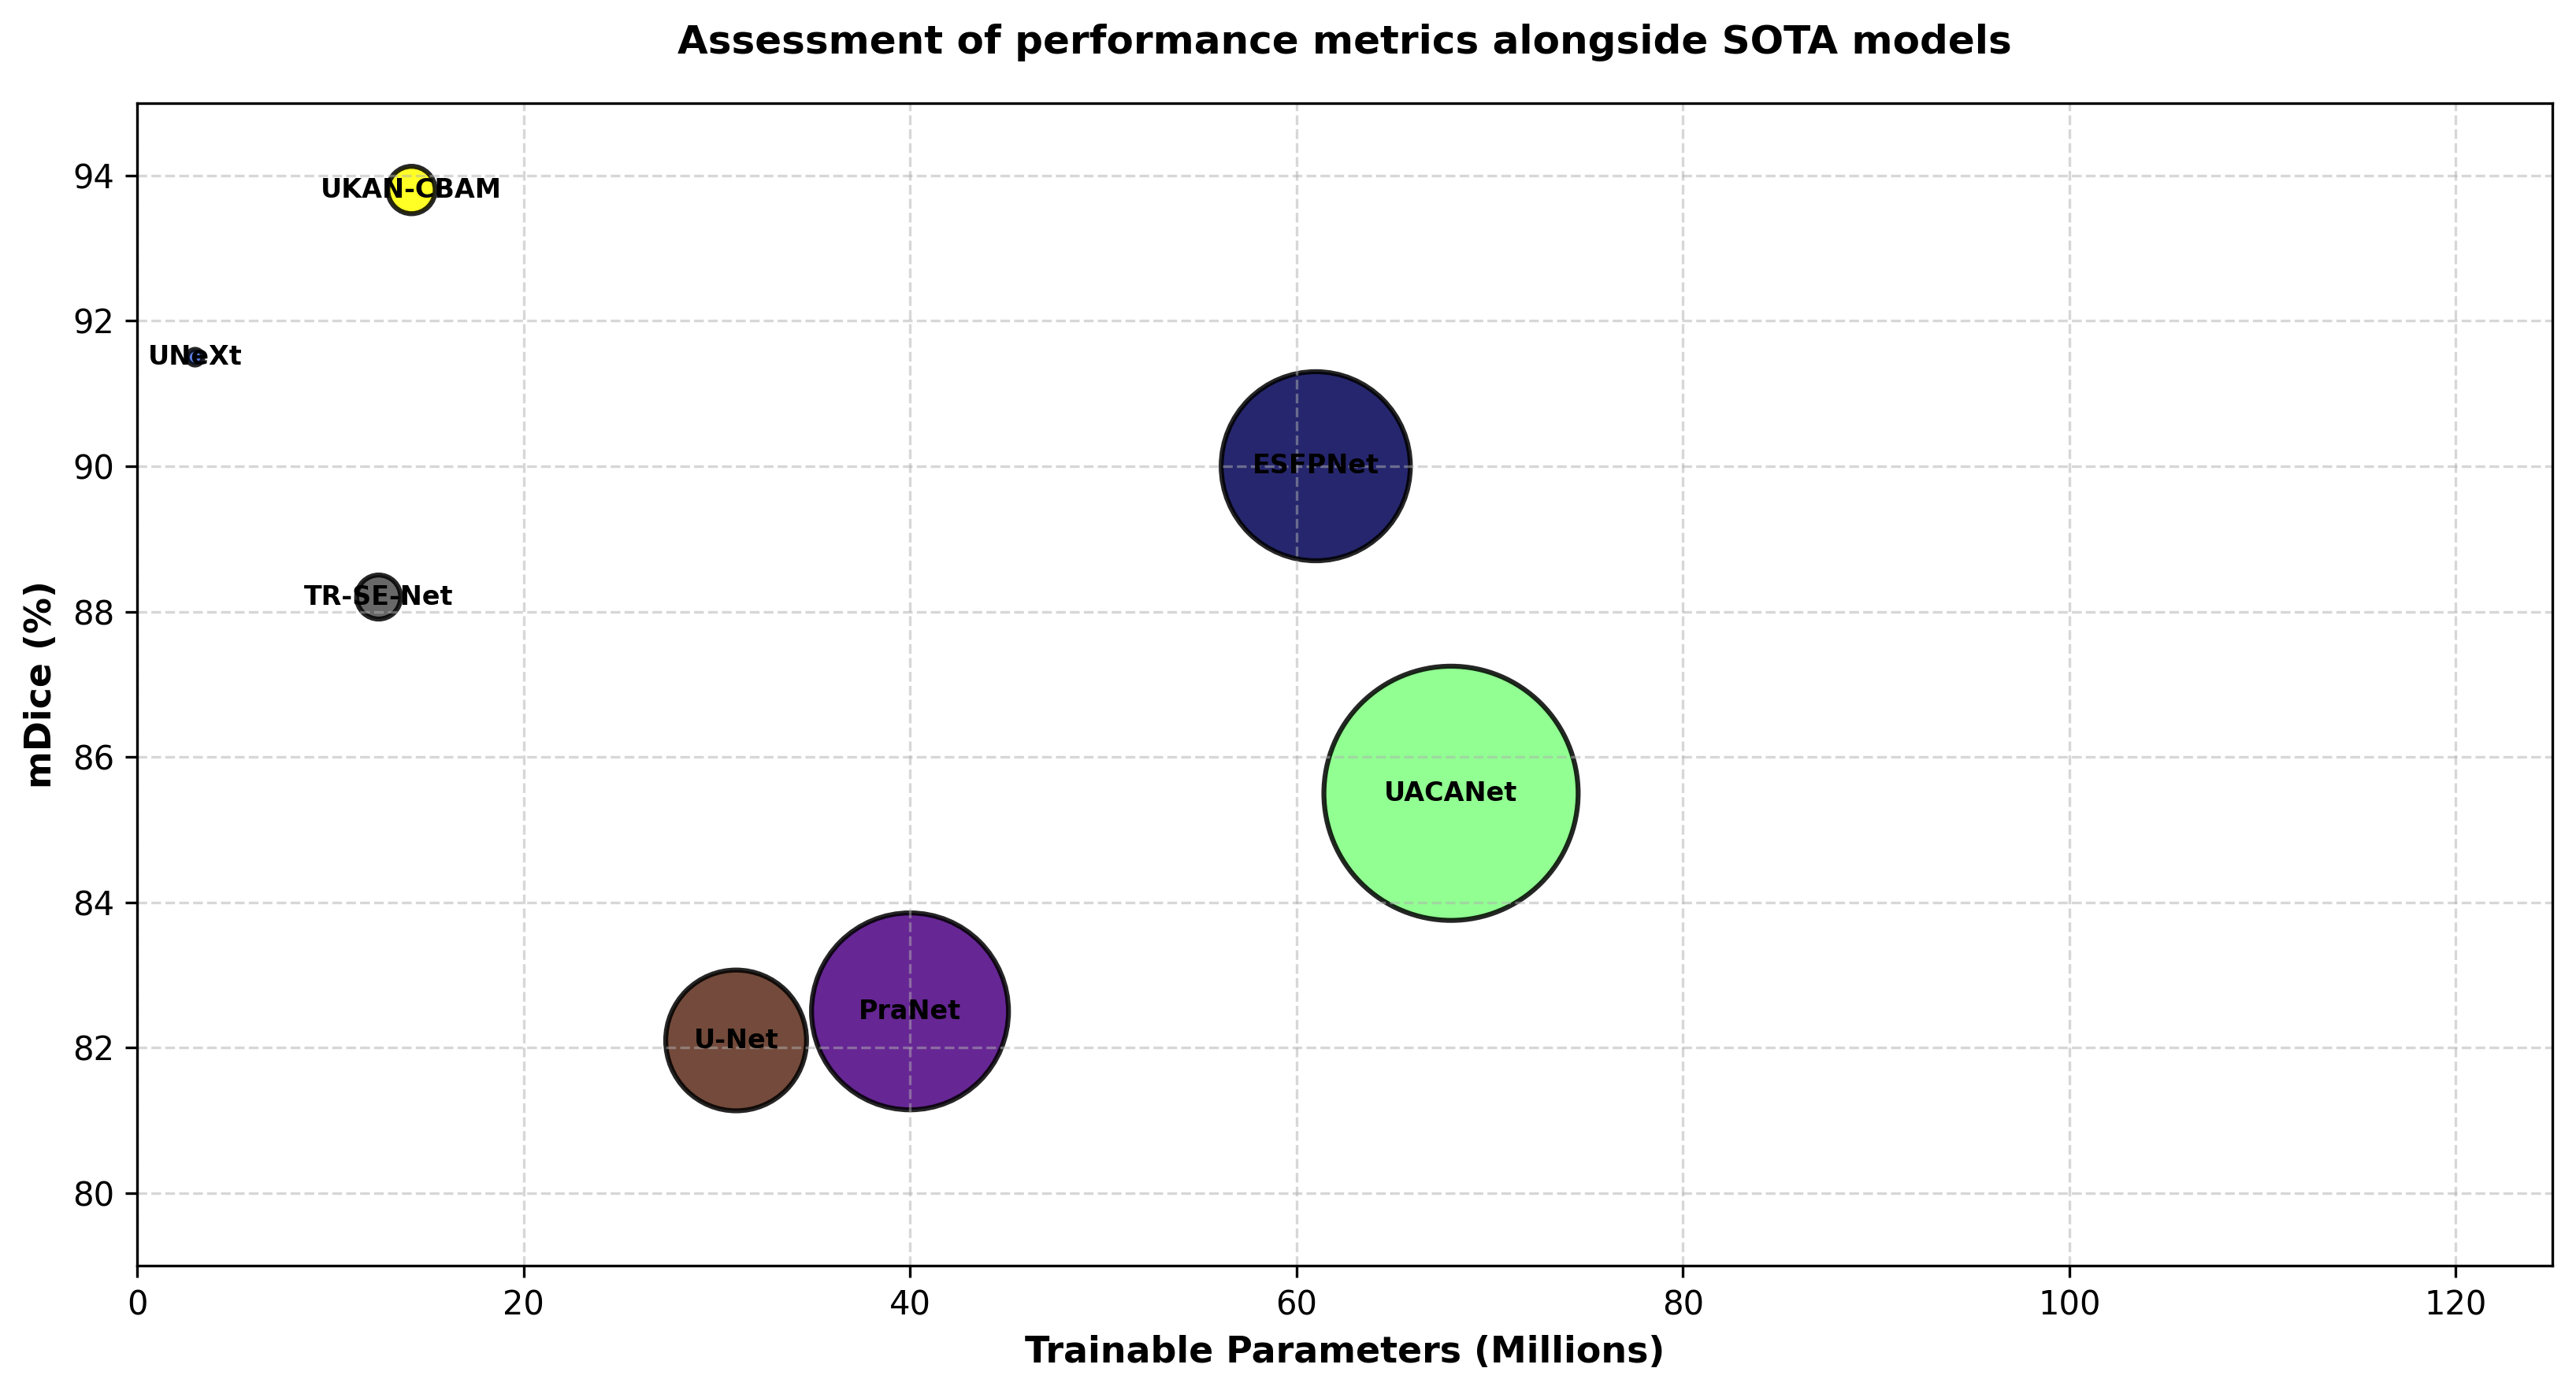

In [13]:
import matplotlib.pyplot as plt

# ১. আপনার মডেলগুলোর ডেটা সেট করুন
models_data = {
    'Model': ['U-Net', 'PraNet', 'UACANet', 'ESFPNet', 'TR-SE-Net', 'UNeXt', 'UKAN-CBAM'],
    'Params_M': [31.0, 40.0, 68.0, 61.0, 12.5, 3.0, 14.2],  # X-axis
    'mDice': [82.1, 82.5, 85.5, 90.0, 88.2, 91.5, 93.8],      # Y-axis
    'GFLOPs': [46.0, 90.0, 150.0, 83.0, 4.5, 0.57, 5.214],    # Bubble Size
    'Color': ['#5a2a18', '#4b0082', '#7eff7e', '#000055', '#4d4d4d', '#4169e1', '#ffff00']
}

# ২. বাবল এরিয়া দৃশ্যমান করার জন্য GFLOPs স্কেলিং
bubble_sizes = [g * 40 for g in models_data['GFLOPs']]

# ৩. ফিগার তৈরি
fig, ax = plt.subplots(figsize=(11, 6), dpi=300)

# ৪. বাবল প্লট (Scatter Chart)
scatter = ax.scatter(
    models_data['Params_M'], 
    models_data['mDice'], 
    s=bubble_sizes, 
    c=models_data['Color'], 
    alpha=0.85, 
    edgecolors='black', 
    linewidth=1.5
)

# ৫. প্রতিটি বাবলের ভেতরে মডেলের নাম লেখা
for i, txt in enumerate(models_data['Model']):
    ax.annotate(
        txt, 
        (models_data['Params_M'][i], models_data['mDice'][i]),
        fontsize=8, 
        fontweight='bold', 
        ha='center', 
        va='center'
    )

# ৬. এক্সিস ও গ্রিড কাস্টমাইজেশন
ax.set_xlabel('Trainable Parameters (Millions)', fontsize=11, fontweight='bold')
ax.set_ylabel('mDice (%)', fontsize=11, fontweight='bold')
ax.set_ylim(79, 95)
ax.set_xlim(0, 125)
ax.grid(True, linestyle='--', alpha=0.5)

plt.title('Assessment of performance metrics alongside SOTA models', fontsize=12, fontweight='bold', pad=15)
plt.tight_layout()

# ৭. সেভ করা (Paper ready High-Res Image)
plt.savefig('sota_tradeoff_chart.png', dpi=300)
plt.show()

POLYP DETECTION & EXPLAINABILITY REPORT — GENERATING
Loading Y-Net model...
Running classification (ELM ensemble)...
Computing segmentation mask & overlay...
Classifying polyp size...
Computing Feature Map...
Computing Score-CAM...
Computing occlusion sensitivity...
Computing SHAP explanation...
Assembling robust horizontal report figure...
Professional Report saved to: ./polyp_medical_report.png


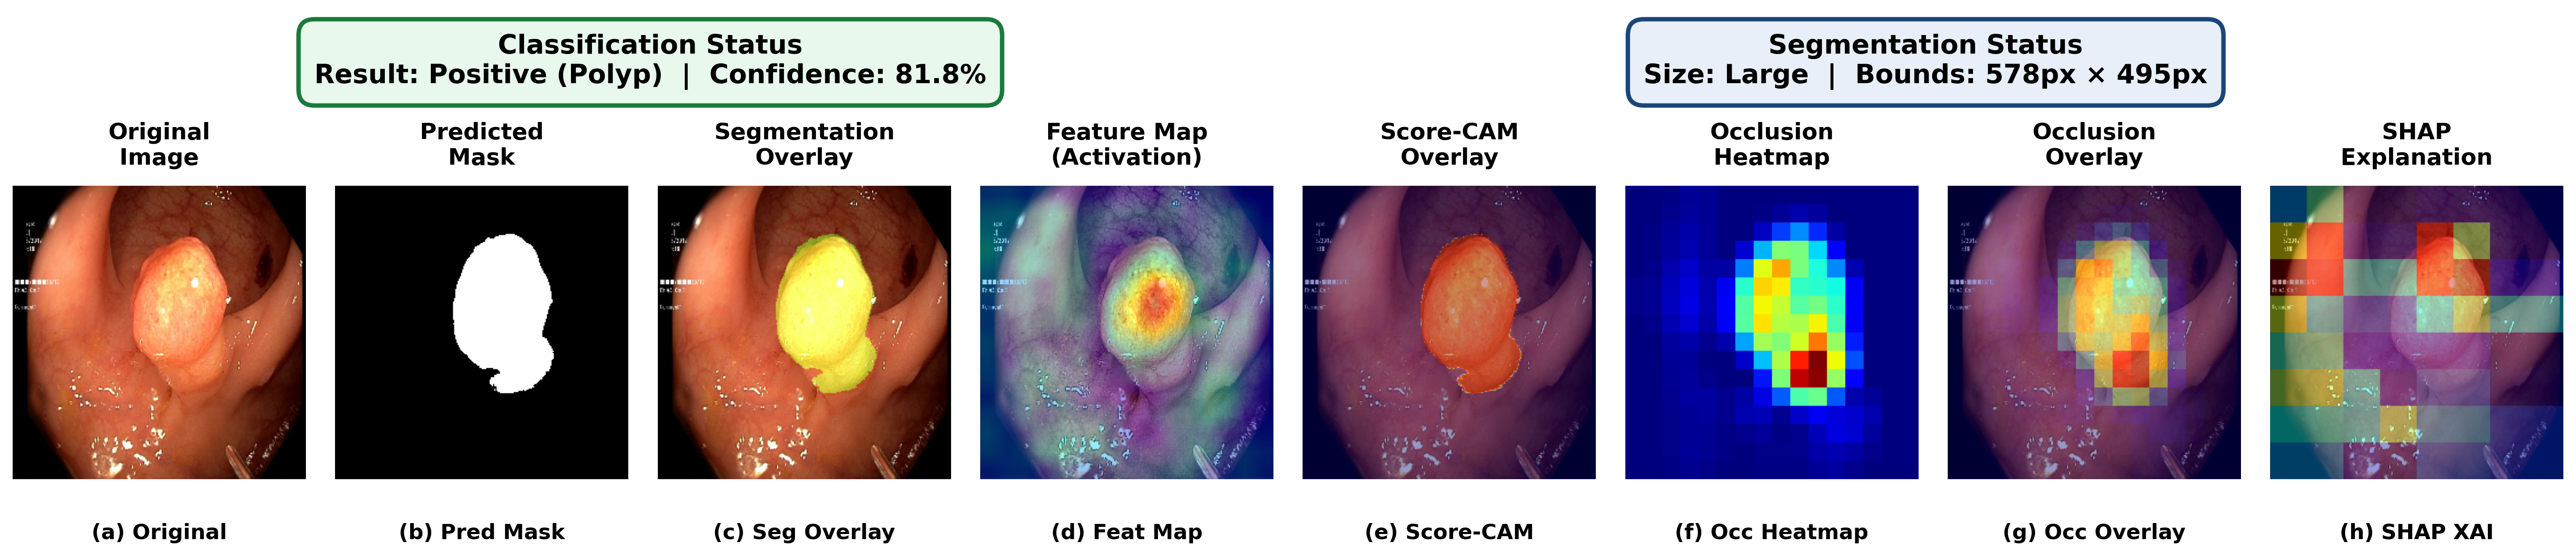

In [16]:
"""
generate_medical_report.py
============================================================
Unified Polyp Detection & Explainability Report Generator
------------------------------------------------------------
(Updated Grid-based Horizontal Layout with Status Cards)
============================================================
"""

import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import shap

# ============================================================
# 1. Custom Layer (required for Keras to deserialize the model)
# ============================================================
@tf.keras.utils.register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    """Self outer-product Pairwise Correlation Coefficient (PCC) layer."""

    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        epsilon = 1e-8
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(
            tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1)
        )
        return tf.keras.layers.Flatten()(pcc_matrix)

    def get_config(self):
        return super().get_config()

# ============================================================
# 2. Shared Preprocessing Pipeline
# ============================================================
def _preprocess_image(image_path, img_size=256):
    raw_bgr = cv2.imread(image_path)
    if raw_bgr is None:
        raise ValueError(f"cv2 could not read image: {image_path}")

    img_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (img_size, img_size))

    lab = cv2.cvtColor(img_res, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l_channel)
    limg = cv2.merge((cl, a_channel, b_channel))
    enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)

    median_blur = cv2.medianBlur(enhanced_img, 3)
    sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)

    normalized_tensor = np.expand_dims(sharpened / 255.0, axis=0).astype(np.float32)
    return img_res, sharpened, normalized_tensor

# ============================================================
# 3. ELM Classification Pipeline (loads .npz artifact)
# ============================================================
def _load_elm_pipeline(elm_artifact_path):
    elm = np.load(elm_artifact_path, allow_pickle=True)
    selector_support = elm["selector_support"]
    scaler_center = elm["scaler_center_"]
    scaler_scale = elm["scaler_scale_"]
    W_input_all = elm["W_input"]
    b_input_all = elm["b_input"]
    W_out_all = elm["ensemble_weights"]

    if selector_support.dtype == bool:
        selected_indices = np.where(selector_support)[0]
    else:
        selected_indices = selector_support.astype(int)

    b_input_vec = b_input_all.reshape(1, -1)
    lambda_outputs = W_out_all.reshape(W_out_all.shape[0], -1, 1)
    ensemble = [(W_input_all, b_input_vec, w_out) for w_out in lambda_outputs]

    return selected_indices, scaler_center, scaler_scale, ensemble

def _elm_predict(feats_scaled, ensemble):
    scores = []
    for W_input, b_input, W_out in ensemble:
        H = np.tanh(np.dot(feats_scaled, W_input) + b_input)
        raw_score = np.dot(H, W_out)
        scores.append(raw_score)
    raw_output = np.mean(scores, axis=0).flatten()
    calibrated_prob = 1 / (1 + np.exp(-raw_output))
    return calibrated_prob

# ============================================================
# 4. Segmentation Mask + Overlay
# ============================================================
def _get_segmentation(seg_model, normalized_tensor, base_rgb, threshold=0.5):
    pred = seg_model(normalized_tensor, training=False)
    pred_mask = pred[0][0].numpy() if isinstance(pred, (list, tuple)) else pred[0].numpy()
    pred_spatial = pred_mask[:, :, 0] if pred_mask.ndim == 3 else pred_mask
    pred_bin = (pred_spatial > threshold).astype(np.uint8) * 255

    overlay_img = base_rgb.copy()
    green_mask = np.zeros_like(base_rgb)
    green_mask[:, :, 1] = pred_bin
    cv2.addWeighted(green_mask, 0.4, overlay_img, 1.0, 0, overlay_img)

    return pred_bin, overlay_img

# ============================================================
# 5. Feature Map (Bottleneck Activation)
# ============================================================
def _get_feature_map(model, normalized_tensor, base_rgb, target_layer_name, img_size):
    feature_model = tf.keras.models.Model(
        inputs=model.input, outputs=model.get_layer(target_layer_name).output
    )
    features = feature_model(normalized_tensor, training=False)
    features = features[0].numpy()

    feature_heatmap = np.mean(features, axis=-1)
    feature_heatmap = np.maximum(feature_heatmap, 0)
    max_val = np.max(feature_heatmap)
    if max_val > 0:
        feature_heatmap = np.where(feature_heatmap > (0.1 * max_val), feature_heatmap, 0.0)
        feature_heatmap = feature_heatmap / np.max(feature_heatmap)

    heatmap_resized = cv2.resize(feature_heatmap, (img_size, img_size))
    color_heatmap = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    color_heatmap_rgb = cv2.cvtColor(color_heatmap, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(base_rgb, 0.6, color_heatmap_rgb, 0.4, 0)
    return overlay

# ============================================================
# 5b. Polyp Size Classification
# ============================================================
def _classify_polyp_size(pred_mask, orig_shape, img_size):
    orig_h, orig_w = orig_shape[:2]
    scale_y = orig_h / img_size
    scale_x = orig_w / img_size

    binary_mask = (pred_mask > 0).astype(np.uint8)
    num_labels, labels_im, stats, _ = cv2.connectedComponentsWithStats(binary_mask, connectivity=8)

    if num_labels <= 1:
        return {"label": "No Polyp", "height_px": 0, "width_px": 0, "bbox": None}

    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    x, y, w, h, area = stats[largest_label]

    height_px = int(round(h * scale_y))
    width_px = int(round(w * scale_x))

    if height_px <= 100 and width_px <= 100:
        size_label = "Small"
    elif height_px >= 200 and width_px >= 200:
        size_label = "Large"
    else:
        size_label = "Medium"

    return {"label": size_label, "height_px": height_px, "width_px": width_px, "bbox": (x, y, w, h)}

# ============================================================
# 6. Score-CAM (Segmentation XAI)
# ============================================================
def _get_score_cam(model, normalized_tensor, base_rgb, img_size, max_n_features=32):
    target_layer_name = [
        layer.name for layer in model.layers
        if isinstance(layer, (tf.keras.layers.Conv2D, tf.keras.layers.DepthwiseConv2D))
    ][-1]

    score_cam_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(target_layer_name).output, model.output],
    )

    features, predictions = score_cam_model(normalized_tensor, training=False)
    features = features[0].numpy()
    h, w, c = features.shape
    cam = np.zeros((h, w), dtype=np.float32)
    channels_to_process = min(c, max_n_features)

    for i in range(channels_to_process):
        feature_map = features[:, :, i]
        upsampled_map = cv2.resize(feature_map, (img_size, img_size))
        map_min, map_max = upsampled_map.min(), upsampled_map.max()
        if map_max - map_min > 1e-5:
            normalized_map = (upsampled_map - map_min) / (map_max - map_min)
        else:
            normalized_map = upsampled_map
        masked_input = normalized_tensor[0] * np.expand_dims(normalized_map, axis=-1)
        masked_input_tensor = np.expand_dims(masked_input, axis=0)
        g_pred = score_cam_model(masked_input_tensor, training=False)[1]
        score = tf.reduce_mean(g_pred[0]).numpy() if isinstance(g_pred, (list, tuple)) else tf.reduce_mean(g_pred).numpy()
        cam += score * feature_map

    cam = np.maximum(cam, 0)
    if cam.max() > 0:
        cam = cam / cam.max()
    cam = cv2.resize(cam, (img_size, img_size))

    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(base_rgb, 0.6, heatmap_rgb, 0.4, 0)
    return overlay

# ============================================================
# 7. Occlusion Sensitivity (Segmentation XAI)
# ============================================================
def _get_occlusion_sensitivity(model, normalized_tensor, base_rgb, img_size, patch_size=32, stride=16):
    raw_img = normalized_tensor[0]
    h, w, _ = raw_img.shape

    base_preds = model(normalized_tensor, training=False)
    base_mask = base_preds[0][0].numpy() if isinstance(base_preds, (list, tuple)) else base_preds[0].numpy()
    base_score = np.mean(base_mask)

    sensitivity_map = np.zeros((h, w), dtype=np.float32)
    overlap_counts = np.zeros((h, w), dtype=np.float32)

    for y in range(0, h - patch_size + 1, stride):
        for x in range(0, w - patch_size + 1, stride):
            masked_img = np.copy(raw_img)
            masked_img[y:y + patch_size, x:x + patch_size, :] = 0.5
            masked_tensor = np.expand_dims(masked_img, axis=0)

            occ_preds = model(masked_tensor, training=False)
            occ_mask = occ_preds[0][0].numpy() if isinstance(occ_preds, (list, tuple)) else occ_preds[0].numpy()
            occ_score = np.mean(occ_mask)

            score_drop = max(0, base_score - occ_score)
            sensitivity_map[y:y + patch_size, x:x + patch_size] += score_drop
            overlap_counts[y:y + patch_size, x:x + patch_size] += 1.0

    overlap_counts[overlap_counts == 0] = 1.0
    sensitivity_map /= overlap_counts

    map_min, map_max = sensitivity_map.min(), sensitivity_map.max()
    if map_max - map_min > 1e-5:
        sensitivity_map = (sensitivity_map - map_min) / (map_max - map_min)

    heatmap = cv2.applyColorMap(np.uint8(255 * sensitivity_map), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(base_rgb, 0.6, heatmap_rgb, 0.4, 0)

    return sensitivity_map, overlay

# ============================================================
# 8. SHAP (Classification XAI only)
# ============================================================
# ============================================================
# 8. SHAP (Classification XAI Overlap)
# ============================================================
def _get_shap_overlay(image_path, feature_extractor, selected_indices, scaler_center, scaler_scale, ensemble, base_rgb, img_size=256, max_evals=300, batch_size=32):
    def full_pipeline_predict(images_uint8):
        batch = images_uint8.astype(np.float32) / 255.0
        feats = feature_extractor(batch, training=False).numpy()
        feats_sel = feats[:, selected_indices]
        feats_scaled = (feats_sel - scaler_center) / scaler_scale
        return _elm_predict(feats_scaled, ensemble)

    raw_bgr = cv2.imread(image_path)
    img_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    img_res = cv2.resize(img_rgb, (img_size, img_size)).astype(np.uint8)

    pred_prob = full_pipeline_predict(np.expand_dims(img_res, axis=0))[0]

    masker = shap.maskers.Image("blur(128,128)", img_res.shape)
    explainer = shap.Explainer(full_pipeline_predict, masker)
    shap_values = explainer(
        np.expand_dims(img_res, axis=0), max_evals=max_evals, batch_size=batch_size
    )

    # Extract manual SHAP values for the first (and only) image
    sv = shap_values.values[0]
    
    # Handle dimension if it includes output class axis (H, W, C, 1)
    if sv.ndim == 4:
        sv = sv[..., 0]
        
    # Create 2D Heatmap (sum across color channels)
    shap_map = np.abs(sv).sum(axis=-1)
    
    # Normalize between 0 and 1
    map_min, map_max = shap_map.min(), shap_map.max()
    if map_max - map_min > 1e-5:
        shap_map = (shap_map - map_min) / (map_max - map_min)
    else:
        shap_map = np.zeros_like(shap_map)

    # Resize to match base_rgb and apply Colormap
    shap_map = cv2.resize(shap_map, (img_size, img_size))
    heatmap = cv2.applyColorMap(np.uint8(255 * shap_map), cv2.COLORMAP_JET)
    heatmap_rgb = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    
    # Overlay onto the original base_rgb image
    overlay = cv2.addWeighted(base_rgb, 0.6, heatmap_rgb, 0.4, 0)

    return pred_prob, overlay

# ============================================================
# 9. MAIN: Composite Medical Report Generator (Horizontal Grid)
# ============================================================
def generate_polyp_medical_report(
    image_path,
    model_path,
    elm_artifact_path,
    output_path="./polyp_medical_report.png",
    img_size=256,
    detection_threshold=0.60,
    seg_mask_threshold=0.5,
    feature_map_layer="clf_pd_cnn",
    shap_max_evals=300,
):
    print("=" * 70)
    print("POLYP DETECTION & EXPLAINABILITY REPORT — GENERATING")
    print("=" * 70)

    print("Loading Y-Net model...")
    model = tf.keras.models.load_model(model_path, custom_objects={"KerasPCCLayer": KerasPCCLayer}, compile=False)
    seg_model = tf.keras.models.Model(inputs=model.input, outputs=model.outputs[0])
    feature_extractor = tf.keras.Model(inputs=model.input, outputs=model.get_layer("clf_pcc_layer").output)

    base_rgb, sharpened, normalized_tensor = _preprocess_image(image_path, img_size)

    print("Running classification (ELM ensemble)...")
    selected_indices, scaler_center, scaler_scale, ensemble = _load_elm_pipeline(elm_artifact_path)
    feats = feature_extractor(normalized_tensor, training=False).numpy()
    feats_sel = feats[:, selected_indices]
    feats_scaled = (feats_sel - scaler_center) / scaler_scale
    detection_prob = float(_elm_predict(feats_scaled, ensemble)[0])
    
    # Classification Status
    is_polyp = detection_prob >= detection_threshold
    detection_label = "Positive (Polyp)" if is_polyp else "Negative (No Polyp)"

    print("Computing segmentation mask & overlay...")
    pred_mask, seg_overlay = _get_segmentation(seg_model, normalized_tensor, base_rgb, seg_mask_threshold)

    print("Classifying polyp size...")
    orig_shape = cv2.imread(image_path).shape
    size_info = _classify_polyp_size(pred_mask, orig_shape, img_size)

    print("Computing Feature Map...")
    feature_map_overlay = _get_feature_map(model, normalized_tensor, sharpened, feature_map_layer, img_size)

    print("Computing Score-CAM...")
    score_cam_overlay = _get_score_cam(seg_model, normalized_tensor, base_rgb, img_size)

    print("Computing occlusion sensitivity...")
    occ_heatmap, occ_overlay = _get_occlusion_sensitivity(seg_model, normalized_tensor, base_rgb, img_size)

    print("Computing SHAP explanation...")
    _, shap_overlay = _get_shap_overlay(image_path, feature_extractor, selected_indices, scaler_center, scaler_scale, ensemble, base_rgb, img_size=img_size, max_evals=shap_max_evals)
    # ============================================================
    # 10. PLOTTING: Wide Horizontal Layout (SOTA Paper Style)
    # ============================================================
    print("Assembling robust horizontal report figure...")

    # Create a wide figure: 1 row for Status Cards, 1 row for 8 images
    fig = plt.figure(figsize=(26, 6), dpi=300, facecolor="white")
    gs = gridspec.GridSpec(2, 8, height_ratios=[0.25, 1], hspace=0.1, wspace=0.1)

    # --- 10A. Top Status Banner (Card Style) ---
    ax_header = fig.add_subplot(gs[0, :])
    ax_header.axis("off")

    # Styling for Cards
    clf_color = "#e8f8ec" if is_polyp else "#f8e8e8"
    clf_edge = "#1a7a3c" if is_polyp else "#a31a1a"
    seg_color = "#e8eff8"
    seg_edge = "#1a467a"

    bbox_clf = dict(boxstyle="round,pad=0.6", fc=clf_color, ec=clf_edge, lw=2.5)
    bbox_seg = dict(boxstyle="round,pad=0.6", fc=seg_color, ec=seg_edge, lw=2.5)

    clf_text = f"Classification Status\nResult: {detection_label}  |  Confidence: {detection_prob*100:.1f}%"
    
    if size_info["label"] == "No Polyp":
        seg_text = f"Segmentation Status\nResult: No Mask Detected"
    else:
        seg_text = f"Segmentation Status\nSize: {size_info['label']}  |  Bounds: {size_info['height_px']}px × {size_info['width_px']}px"

    # Position the cards on the header
    ax_header.text(0.25, 0.5, clf_text, ha="center", va="center", fontsize=15, fontweight="bold", color="black", bbox=bbox_clf)
    ax_header.text(0.75, 0.5, seg_text, ha="center", va="center", fontsize=15, fontweight="bold", color="black", bbox=bbox_seg)

    # --- 10B. Image Panels (1x8 Grid) ---
    panels = [
        (base_rgb, "Original\nImage", "(a) Original", None),
        (pred_mask, "Predicted\nMask", "(b) Pred Mask", "gray"),
        (seg_overlay, "Segmentation\nOverlay", "(c) Seg Overlay", None),
        (feature_map_overlay, "Feature Map\n(Activation)", "(d) Feat Map", None),
        (score_cam_overlay, "Score-CAM\nOverlay", "(e) Score-CAM", None),
        (occ_heatmap, "Occlusion\nHeatmap", "(f) Occ Heatmap", "jet"),
        (occ_overlay, "Occlusion\nOverlay", "(g) Occ Overlay", None)
    ]

    # Plot the first 7 panels
    for i, (img_data, title, label, cmap) in enumerate(panels):
        ax = fig.add_subplot(gs[1, i])
        if cmap:
            ax.imshow(img_data, cmap=cmap)
        else:
            ax.imshow(img_data)
        
        # Remove borders and ticks for a clean professional look
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)
            
        ax.set_title(title, fontsize=13, fontweight="bold", pad=12)
        ax.text(0.5, -0.15, label, transform=ax.transAxes, fontsize=12, fontweight="bold", ha="center", va="top")

    # Plot the 8th panel (SHAP)
    ax_shap = fig.add_subplot(gs[1, 7])
    
    # Directly show the overlapped SHAP image
    ax_shap.imshow(shap_overlay)
    
    ax_shap.set_xticks([])
    ax_shap.set_yticks([])
    for spine in ax_shap.spines.values():
        spine.set_visible(False)
        
    ax_shap.set_title("SHAP\nExplanation", fontsize=13, fontweight="bold", pad=12)
    ax_shap.text(0.5, -0.15, "(h) SHAP XAI", transform=ax_shap.transAxes, fontsize=12, fontweight="bold", ha="center", va="top")
    for spine in ax_shap.spines.values():
        spine.set_visible(False)
        
    ax_shap.set_title("SHAP\nExplanation", fontsize=13, fontweight="bold", pad=12)
    ax_shap.text(0.5, -0.15, "(h) SHAP XAI", transform=ax_shap.transAxes, fontsize=12, fontweight="bold", ha="center", va="top")


    # Save final composite
    plt.subplots_adjust(bottom=0.2) # Ensure labels at the bottom aren't cut off
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    plt.close(fig)

    print("=" * 70)
    print(f"Professional Report saved to: {output_path}")
    print("=" * 70)

    return output_path

# ============================================================
# Example usage
# ============================================================
if __name__ == "__main__":
    MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
    ELM_ARTIFACT_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/elm_artifacts.npz"
    IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001304.jpg"


    # Uncomment and set proper paths to test
    generate_polyp_medical_report(
        image_path=IMAGE_PATH,
        model_path=MODEL_PATH,
        elm_artifact_path=ELM_ARTIFACT_PATH,
        output_path="./polyp_medical_report.png",
    )
    from IPython.display import Image, display
    display(Image(filename="./polyp_medical_report.png"))